# Lecture 5 — Model Limits and Decision Context

This classroom notebook contains complete worked examples **5.1–5.25**. The notes and slides use the same public numbers. Homework is a separate scaffolded notebook; it cites these sections and leaves only specified code blanks.

Read each Markdown step, run its small code cell, inspect the figure and interpret the result. Lectures 1–3 covered Python basics; no separate basic-operation recording is required here.

The local seed-417 demand data are the same teaching simulation used in Lecture 4. Its later block has already been inspected: it is reused for instruction, not advertised as new unseen evidence. Constructed probability, regime and state examples are labeled separately. No network download or substitute dataset changes the lesson.

## Contents
- [5.1 — Separate the forecast from the action](#example-5-1)
- [5.2 — A tree does not extend a trend](#example-5-2)
- [5.3 — Distinguish three ways the world can change](#example-5-3)
- [5.4 — Check support without claiming it proves safety](#example-5-4)
- [5.5 — Monitor errors only after outcomes arrive](#example-5-5)
- [5.6 — Connect an alert to an explicit fallback rule](#example-5-6)
- [5.7 — Keep error direction and business units explicit](#example-5-7)
- [5.8 — Calculate asymmetric realized loss](#example-5-8)
- [5.9 — Choose using expected loss before seeing demand](#example-5-9)
- [5.10 — Read a quantile from cumulative probability](#example-5-10)
- [5.11 — Derive the cost-implied quantile direction](#example-5-11)
- [5.12 — Impose a feasible action set](#example-5-12)
- [5.13 — Separate prediction accuracy from decision loss](#example-5-13)
- [5.14 — Reuse the classroom data with an honest chronology](#example-5-14)
- [5.15 — Distinguish training residuals from later forecast errors](#example-5-15)
- [5.16 — Construct an empirical prediction interval](#example-5-16)
- [5.17 — Measure coverage and width together](#example-5-17)
- [5.18 — Make state-dependent width an explicit method](#example-5-18)
- [5.19 — Separate scenarios from assigned probabilities](#example-5-19)
- [5.20 — Do not add daily interval endpoints into a weekly interval](#example-5-20)
- [5.21 — State a threshold rule without inventing an action size](#example-5-21)
- [5.22 — Stress the cost assumptions before recommending](#example-5-22)
- [5.23 — Evaluate a residual-quantile action adjustment honestly](#example-5-23)
- [5.24 — Write a recommendation that can be audited](#example-5-24)
- [5.25 — Replay decisions before attaching later outcomes](#example-5-25)

## Provided preparation
Import tools, locate the local classroom CSV, prepare figure helpers and define the nonnegative shortage/excess loss. The helper reports cost units; it does not assign real business dollar values.

In [1]:
from pathlib import Path
import json,importlib.util
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pathlib import Path
REPOSITORY_ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                       if (folder / 'Coding_Notes').is_dir())
NOTEBOOK_ROOT = REPOSITORY_ROOT / 'Coding_Notes'
HERE=NOTEBOOK_ROOT/'data/Lecture_05'
LECTURE=NOTEBOOK_ROOT/'outputs/Lecture_05'
GRAPH=LECTURE/'figures';OUT=LECTURE/'tables'
GRAPH.mkdir(parents=True,exist_ok=True);OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':17,'axes.spines.top':False,'axes.spines.right':False,'legend.frameon':False})
BLUE='#0072B2';ORANGE='#D55E00';GREEN='#009E73';GRAY='#737373'
results={};manifest=[]
def newfig(n=1):
    fig,axes=plt.subplots(1,n,figsize=(11,3.5),squeeze=False)
    return fig,list(axes[0])
def finish(fig,number,title):
    fig.tight_layout(pad=1.1)
    file=GRAPH/f'ex5_{number:02}.png';fig.savefig(file,dpi=180,bbox_inches='tight',facecolor='white')
    manifest.append({'example':f'5.{number}','figure':str(file.relative_to(LECTURE)),'title':title})
    display(DisplayImage(filename=str(file)));plt.close(fig)
def loss(actual,action,under=3.,over=1.):
    error=np.asarray(actual)-np.asarray(action)
    return under*np.maximum(error,0)+over*np.maximum(-error,0)
def metrics(actual,predicted):
    err=np.asarray(actual)-np.asarray(predicted)
    return {'MAE':float(np.abs(err).mean()),'RMSE':float(np.sqrt((err**2).mean()))}
def interval_metrics(actual,lower,upper):
    actual=np.asarray(actual);lower=np.asarray(lower);upper=np.asarray(upper)
    return {'coverage':float(((lower<=actual)&(actual<=upper)).mean()),'mean_width':float(np.mean(upper-lower))}
def schema(ax,labels):
    ax.axis('off');n=len(labels)
    for i,label in enumerate(labels):
        x=(i+.5)/n;ax.text(x,.55,'\n'.join(__import__('textwrap').wrap(label,14)),ha='center',va='center',fontsize=15,transform=ax.transAxes,bbox=dict(boxstyle='round,pad=.5',fc='white',ec=BLUE,lw=1.5))
        if i<n-1:ax.annotate('',xy=((i+1.18)/n,.55),xytext=((i+.83)/n,.55),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color=GRAY,lw=1.8))


<a id="example-5-1"></a>
## 5.1 — Separate the forecast from the action

**Meaning.** A forecast estimates an unknown outcome. An action is a choice made before that outcome is observed. A decision rule maps information and forecasts to an action; a loss records the consequence after the outcome is known. Shortage means demand exceeds stock; excess means stock exceeds demand.

**Worked sequence.**
1. Hold the outcome at 100 units and the point forecast at 100.
2. Compare stocking 80 with stocking 120; these are choices, not new forecasts.
3. Charge 3 assumed cost units per shortage unit and 1 per excess unit.
4. The actions incur costs 60 and 20 despite sharing one forecast.

### 5.1.1 — Read before running

Set the constructed outcome and the common point forecast to 100. This known outcome is used only to teach after-the-event costing.

**Interpretation check:** The actions incur costs 60 and 20 despite sharing one forecast.

In [2]:
outcome=100
point_forecast=100

### 5.1.2 — Read before running

Create the two candidate stock actions, 80 and 120. Apply the same shortage/excess cost function to each; the point forecast is held fixed.

**Interpretation check:** The actions incur costs 60 and 20 despite sharing one forecast.

In [3]:
actions=np.array([80,120])
action_costs=loss(outcome,actions)

### 5.1.3 — Read before running

Display the computed result without refitting or changing assumptions. The actions incur costs 60 and 20 despite sharing one forecast.

**Interpretation check:** The actions incur costs 60 and 20 despite sharing one forecast.

In [4]:
print(pd.DataFrame({'forecast':point_forecast,'stock':actions,'realized_cost':action_costs}))

   forecast  stock  realized_cost
0       100     80           60.0
1       100    120           20.0


### 5.1.4 — Read before running

Draw the computed comparison: separate the forecast from the action. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The actions incur costs 60 and 20 despite sharing one forecast.

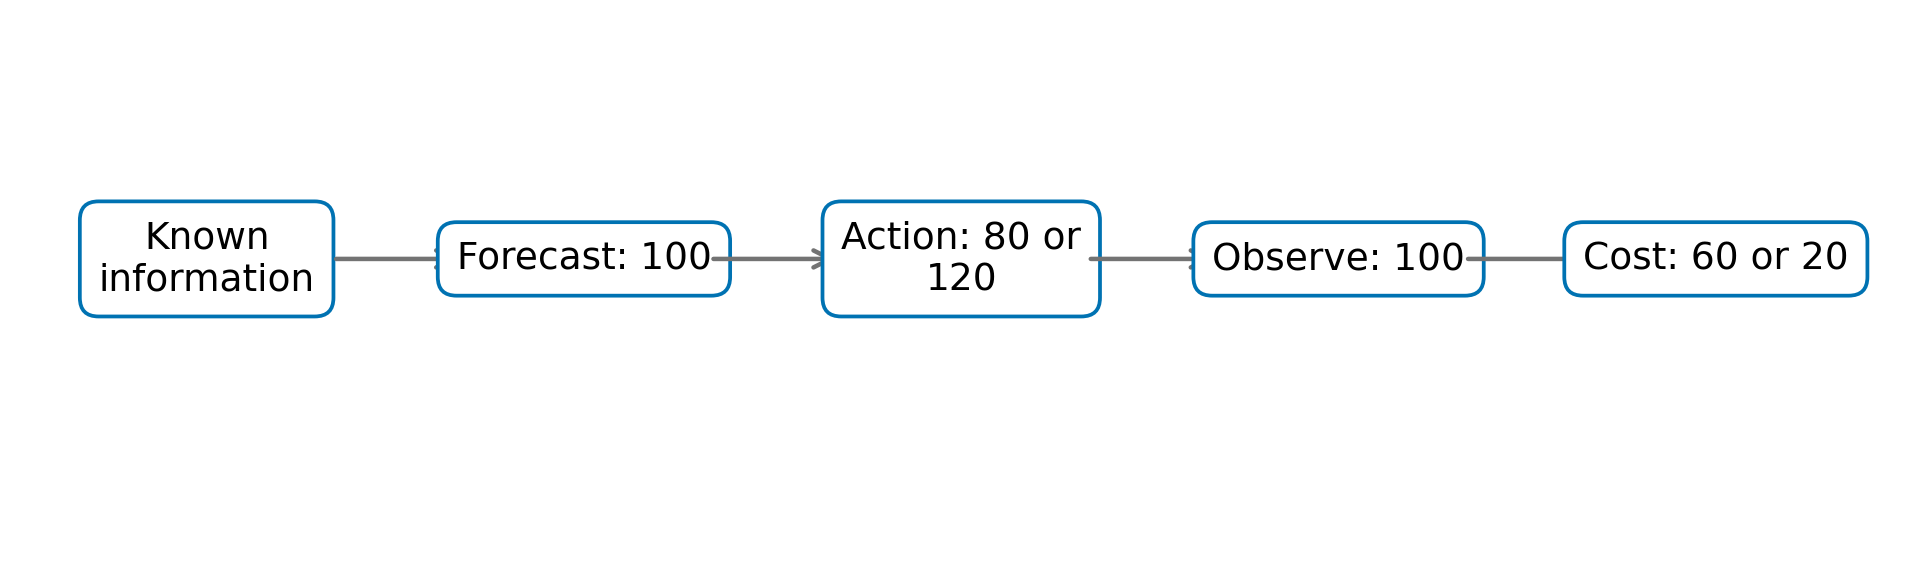

In [5]:
fig,aa=newfig();schema(aa[0],['Known information','Forecast: 100','Action: 80 or 120','Observe: 100','Cost: 60 or 20'])
finish(fig,1,'One forecast can support different actions')
results['5.1']={'actions':actions.tolist(),'costs':action_costs.tolist()}

**Interpretation and limits.** The actions incur costs 60 and 20 despite sharing one forecast.

**Separate homework reference:** HW5.1; complete its marked code blanks in the separate homework notebook.

<a id="example-5-2"></a>
## 5.2 — A tree does not extend a trend

**Meaning.** Extrapolation uses inputs outside the conditions represented in training. A standard mean-valued regression tree returns a stored leaf mean even there; an uncertainty band does not repair a misspecified center.

**Worked sequence.**
1. Reuse the eight traffic/sales pairs from lecture code 4.5.
2. Fit the one-split tree and a linear comparison on identical pairs.
3. Extend the query grid beyond the largest training traffic, 90.
4. At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

### 5.2.1 — Read before running

Store the eight traffic/sales pairs already used in Lecture 4. These paired arrays, not the later query, are the training observations.

**Interpretation check:** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

In [6]:
traffic=np.array([10,20,30,40,60,70,80,90])
sales=np.array([20,24,28,32,60,64,68,72])

### 5.2.2 — Read before running

Fit the depth-one regression tree and the linear comparison to exactly the same eight pairs. Both fitted objects are retained for later queries.

**Interpretation check:** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

In [7]:
stump=DecisionTreeRegressor(max_depth=1,random_state=417).fit(traffic[:,None],sales)
trend=LinearRegression().fit(traffic[:,None],sales)

### 5.2.3 — Read before running

Build a query grid extending beyond the largest observed traffic. Predictions on the grid use the stored rules; no query outcome enters fitting.

**Interpretation check:** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

In [8]:
grid=np.linspace(0,150,301)

### 5.2.4 — Read before running

Display the computed result without refitting or changing assumptions. At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

**Interpretation check:** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

In [9]:
print('At traffic 140:',stump.predict([[140]])[0],trend.predict([[140]])[0])

At traffic 140: 66.0 112.00000000000003


### 5.2.5 — Read before running

Draw the computed comparison: a tree does not extend a trend. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

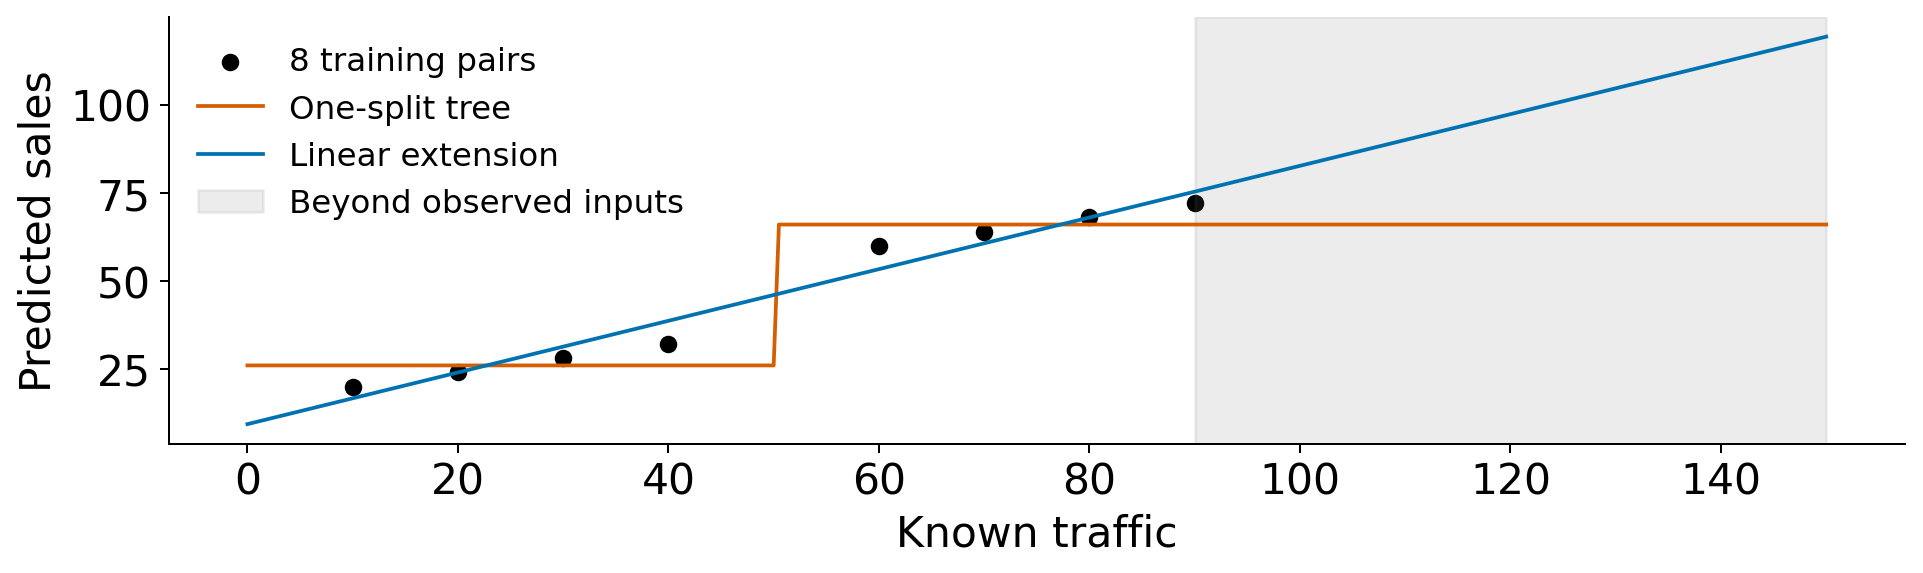

In [10]:
fig,aa=newfig();ax=aa[0];ax.scatter(traffic,sales,c='black',label='8 training pairs')
ax.plot(grid,stump.predict(grid[:,None]),color=ORANGE,label='One-split tree');ax.plot(grid,trend.predict(grid[:,None]),color=BLUE,label='Linear extension')
ax.axvspan(90,150,color=GRAY,alpha=.13,label='Beyond observed inputs');ax.set(xlabel='Known traffic',ylabel='Predicted sales');ax.legend(fontsize=13)
finish(fig,2,'The prediction rule outside training support')
results['5.2']={'tree_at_140':float(stump.predict([[140]])[0]),'linear_at_140':float(trend.predict([[140]])[0])}

**Interpretation and limits.** At traffic 140 the tree still returns 66; the linear extension is an assumption, not verified future truth.

**Separate homework reference:** HW5.2; complete its marked code blanks in the separate homework notebook.

<a id="example-5-3"></a>
## 5.3 — Distinguish three ways the world can change

**Meaning.** A regime change alters a relationship abruptly. Parameter drift changes it gradually. An input shift changes the inputs encountered; it need not change the outcome rule itself.

**Worked sequence.**
1. Use the same horizontal time axis in three separate constructed environments.
2. In the first, the relationship level jumps by 20 starting at day 30.
3. In the second, its level rises gradually starting at day 30.
4. In the third, hold the rule fixed while traffic crosses its earlier maximum.

### 5.3.1 — Read before running

Create a 60-day time axis and a constant reference relationship level of 100.

**Interpretation check:** In the third, hold the rule fixed while traffic crosses its earlier maximum.

In [11]:
days=np.arange(60)
base_level=np.full(60,100.)

### 5.3.2 — Read before running

Construct separate abrupt-jump and gradual-drift environments. Both start at the same level, but the change starting at day 30 follows different rules.

**Interpretation check:** In the third, hold the rule fixed while traffic crosses its earlier maximum.

In [12]:
jump=base_level+20*(days>=30)
drift=base_level+np.maximum(days-30,0)*20/29

### 5.3.3 — Read before running

Create a third environment in which traffic changes from the earlier observed range to higher values. This array changes the inputs rather than specifying a new outcome relationship.

**Interpretation check:** In the third, hold the rule fixed while traffic crosses its earlier maximum.

In [13]:
shifted_input=np.r_[np.linspace(20,80,30),np.linspace(82,140,30)]

### 5.3.4 — Read before running

Draw the computed comparison: distinguish three ways the world can change. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** In the third, hold the rule fixed while traffic crosses its earlier maximum.

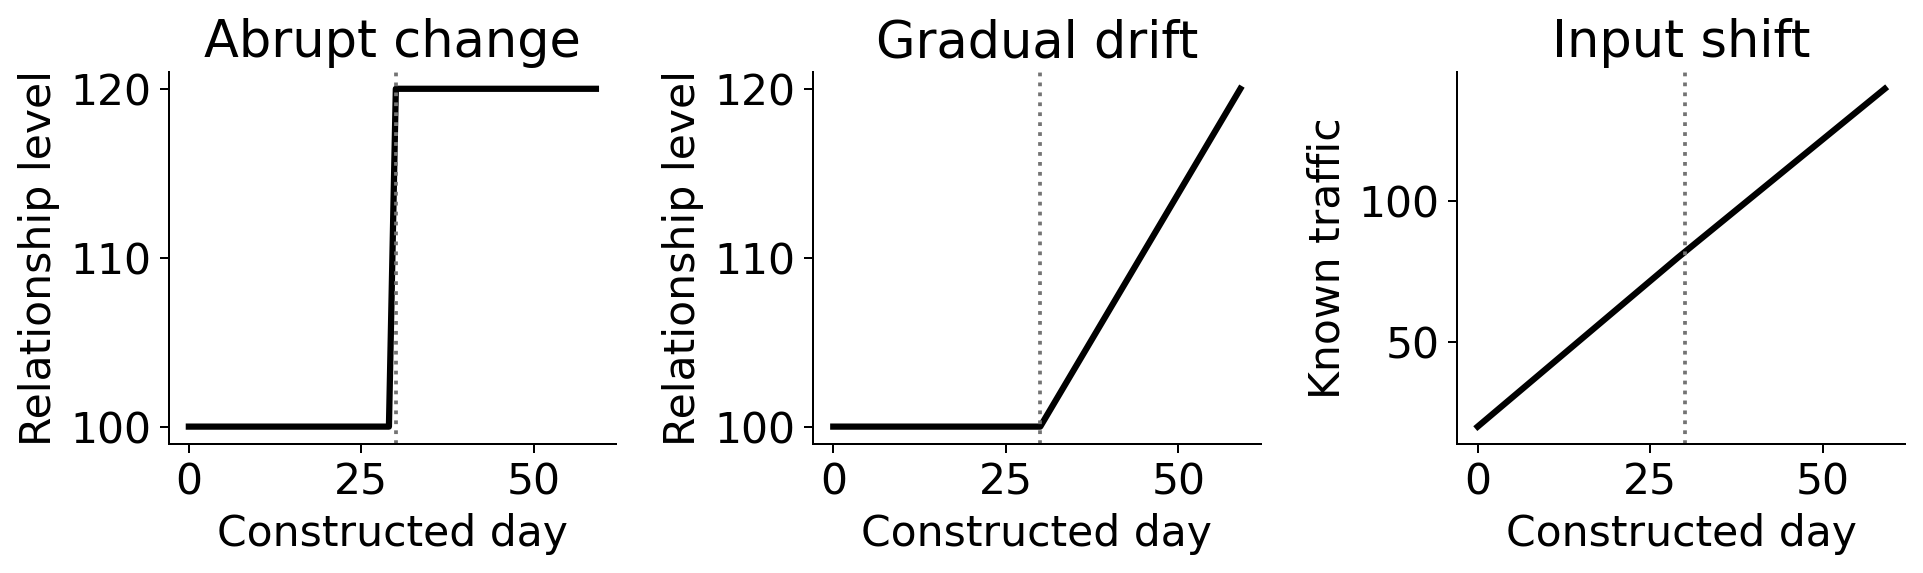

In [14]:
fig,aa=newfig(3)
for ax,values,title,label in zip(aa,[jump,drift,shifted_input],['Abrupt change','Gradual drift','Input shift'],['Relationship level','Relationship level','Known traffic']):
    ax.plot(days,values,color='black',lw=2.5);ax.axvline(30,color=GRAY,ls=':');ax.set(title=title,xlabel='Constructed day',ylabel=label)
finish(fig,3,'Different changes require different diagnoses')
results['5.3']={'jump_size':20,'change_day':30}

**Interpretation and limits.** In the third, hold the rule fixed while traffic crosses its earlier maximum.

**Separate homework reference:** HW5.3; complete its marked code blanks in the separate homework notebook.

<a id="example-5-4"></a>
## 5.4 — Check support without claiming it proves safety

**Meaning.** Training support means the input conditions represented by the training observations. A range check can flag obvious departures. Passing each separate range does not guarantee that an input combination was represented.

**Worked sequence.**
1. Construct paired inputs close to a diagonal band.
2. Compare a familiar pair, an obviously out-of-range pair and an unusual combination inside both marginal ranges.
3. Check coordinate ranges using training observations only.
4. The unusual combination passes both ranges but lies away from the observed pairings.

### 5.4.1 — Read before running

Create paired training inputs near a diagonal band. Their individual ranges will not fully describe which pairings were observed.

**Interpretation check:** The unusual combination passes both ranges but lies away from the observed pairings.

In [15]:
support_x=np.arange(10)
support_y=support_x+np.array([0,.2,-.1,.1,0,.1,-.2,.1,0,.1])

### 5.4.2 — Read before running

Define familiar, obviously out-of-range and unfamiliar-pairing queries. Combine coordinate-wise comparisons using training minima and maxima; this computes a marginal-range flag only.

**Interpretation check:** The unusual combination passes both ranges but lies away from the observed pairings.

In [16]:
queries=np.array([[4,4],[11,11],[2,8]])
marginal_ok=((queries[:,0]>=support_x.min())&(queries[:,0]<=support_x.max())&(queries[:,1]>=support_y.min())&(queries[:,1]<=support_y.max()))

### 5.4.3 — Read before running

Display the computed result without refitting or changing assumptions. The unusual combination passes both ranges but lies away from the observed pairings.

**Interpretation check:** The unusual combination passes both ranges but lies away from the observed pairings.

In [17]:
print(pd.DataFrame({'input_1':queries[:,0],'input_2':queries[:,1],'passes_ranges':marginal_ok}))

   input_1  input_2  passes_ranges
0        4        4           True
1       11       11          False
2        2        8           True


### 5.4.4 — Read before running

Draw the computed comparison: check support without claiming it proves safety. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The unusual combination passes both ranges but lies away from the observed pairings.

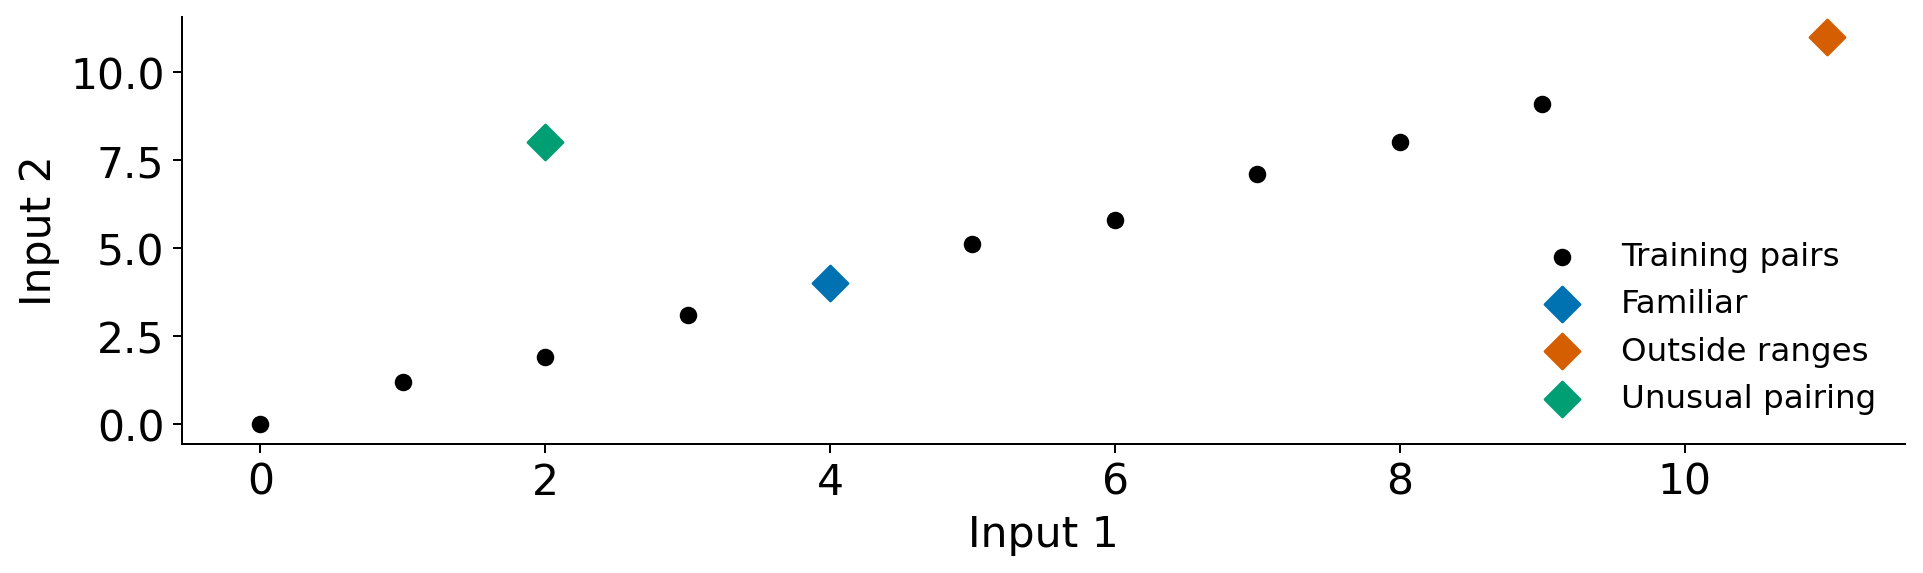

In [18]:
fig,aa=newfig();ax=aa[0];ax.scatter(support_x,support_y,color='black',label='Training pairs')
for pair,label,col in zip(queries,['Familiar','Outside ranges','Unusual pairing'],[BLUE,ORANGE,GREEN]):ax.scatter(*pair,s=100,marker='D',color=col,label=label)
ax.set(xlabel='Input 1',ylabel='Input 2');ax.legend(fontsize=13);finish(fig,4,'Marginal ranges do not describe all joint support')
results['5.4']={'passes_ranges':marginal_ok.tolist()}

**Interpretation and limits.** The unusual combination passes both ranges but lies away from the observed pairings.

**Separate homework reference:** HW5.4; complete its marked code blanks in the separate homework notebook.

<a id="example-5-5"></a>
## 5.5 — Monitor errors only after outcomes arrive

**Meaning.** Operational monitoring checks whether a deployed rule continues to work. A monitoring statistic used before an outcome may include only errors from earlier completed forecasts. An alert is a signal produced when a specified monitoring condition is met.

**Worked sequence.**
1. Keep the forecast at 100 in a separately labeled simulation.
2. Shift the outcome level starting at day 40.
3. Before each target day, average the absolute errors from the previous 10 completed days.
4. An alert above 10 appears with delay; it does not identify the cause of the change.

### 5.5.1 — Read before running

Initialize the stated seed 5417 and the 80-date monitoring sequence. The seed reproduces the teaching simulation; it is not evidence of forecasting performance.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

In [19]:
rng=np.random.default_rng(5417)
monitor_day=np.arange(80)

### 5.5.2 — Read before running

Simulate demand around 100 before day 40 and around 120 afterward. Subtract the unchanged forecast of 100 to obtain realized errors.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

In [20]:
monitor_actual=100+20*(monitor_day>=40)+rng.normal(0,2,80)
monitor_error=monitor_actual-100

### 5.5.3 — Read before running

Shift absolute errors by one date before taking a 10-date rolling mean. The shift keeps the current target outcome out of the monitoring information set.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

In [21]:
past_mae=pd.Series(np.abs(monitor_error)).shift(1).rolling(10).mean()
alerts=past_mae>10

### 5.5.4 — Read before running

Locate the first date whose earlier-error mean crosses the prespecified threshold. The difference from day 40 measures the response delay in this simulation.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

In [22]:
first_alert=int(np.flatnonzero(alerts)[0])

### 5.5.5 — Read before running

Display the computed result without refitting or changing assumptions. An alert above 10 appears with delay; it does not identify the cause of the change.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

In [23]:
print('First alert day:',first_alert)

First alert day: 45


### 5.5.6 — Read before running

Draw the computed comparison: monitor errors only after outcomes arrive. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** An alert above 10 appears with delay; it does not identify the cause of the change.

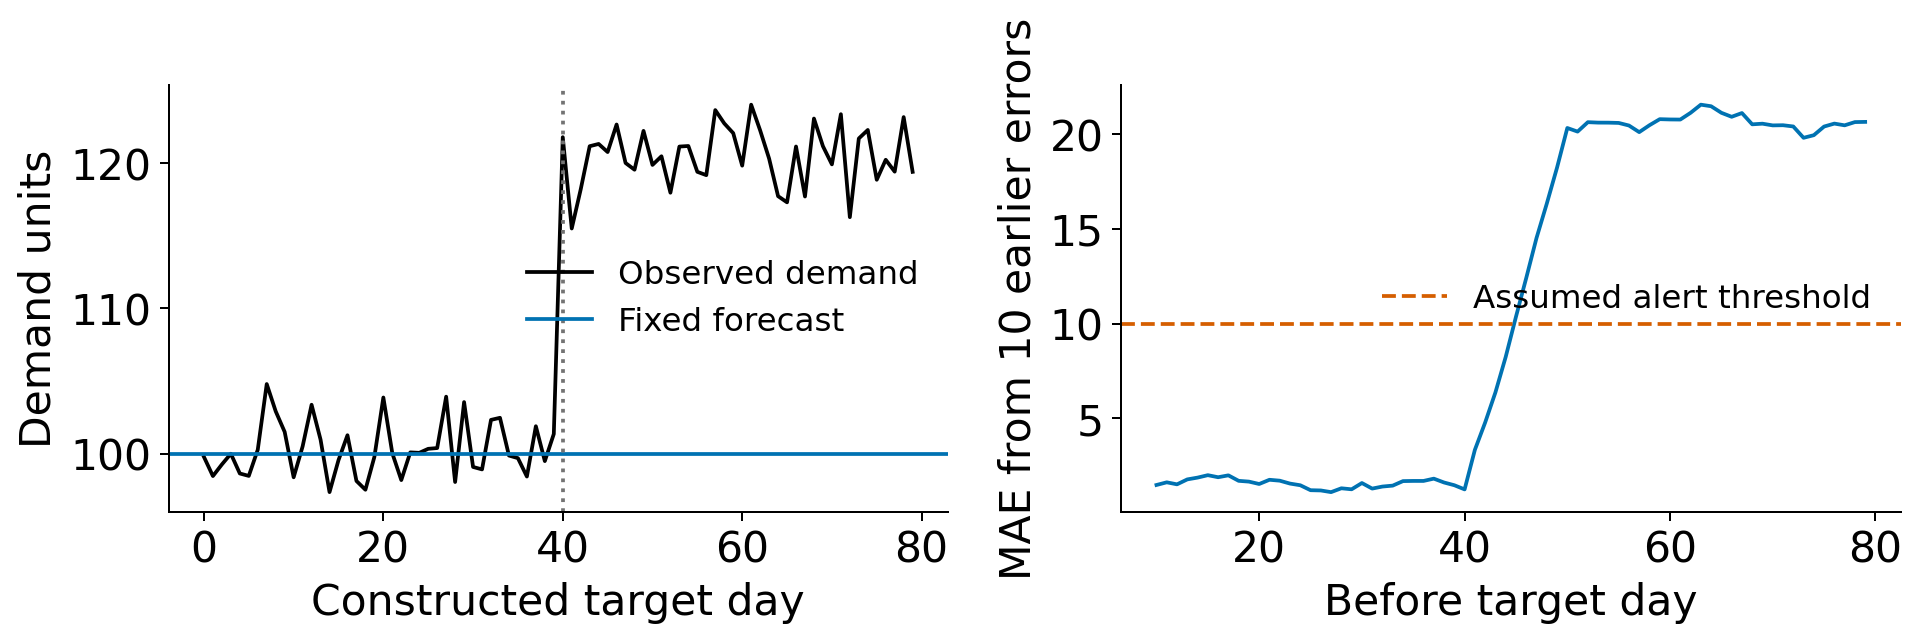

In [24]:
fig,aa=newfig(2);aa[0].plot(monitor_day,monitor_actual,color='black',label='Observed demand');aa[0].axhline(100,color=BLUE,label='Fixed forecast')
aa[0].axvline(40,color=GRAY,ls=':');aa[0].set(xlabel='Constructed target day',ylabel='Demand units');aa[0].legend(fontsize=13)
aa[1].plot(monitor_day,past_mae,color=BLUE);aa[1].axhline(10,color=ORANGE,ls='--',label='Assumed alert threshold');aa[1].set(xlabel='Before target day',ylabel='MAE from 10 earlier errors');aa[1].legend(fontsize=13)
finish(fig,5,'A past-error alert reacts after evidence accumulates')
results['5.5']={'first_alert_day':first_alert,'shift_day':40}

**Interpretation and limits.** An alert above 10 appears with delay; it does not identify the cause of the change.

**Separate homework reference:** HW5.5; complete its marked code blanks in the separate homework notebook.

<a id="example-5-6"></a>
## 5.6 — Connect an alert to an explicit fallback rule

**Meaning.** A fallback is a previously specified action when the ordinary procedure is unsuitable or its inputs are unavailable. An alert is evidence for review, not proof that an automatic refit solves the problem. Capacity is the largest quantity available under the stated operational plan.

**Worked sequence.**
1. Use the alert from example 5.5 rather than looking at the unseen current error.
2. Route an unflagged date to the ordinary decision procedure.
3. Route a flagged date to review, input checks and a predefined capacity plan.
4. Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

### 5.6.1 — Read before running

Copy the before-target alert into a decision table. Label the ordinary and review procedures without using the current outcome to choose between them.

**Interpretation check:** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

In [25]:
alert_rows=pd.DataFrame({'target_day':monitor_day,'alert_before_target':alerts.to_numpy()})
alert_rows['procedure']=np.where(alert_rows.alert_before_target,'Review + capacity plan','Ordinary procedure')

### 5.6.2 — Read before running

Choose the preset 100- or 120-unit stock plan using the earlier alert. Only after the choice, attach its loss against the current observed demand.

**Interpretation check:** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

In [26]:
alert_rows['planned_stock']=np.where(alert_rows.alert_before_target,120,100)
alert_rows['realized_cost']=loss(monitor_actual,alert_rows.planned_stock)

### 5.6.3 — Read before running

Display the computed result without refitting or changing assumptions. Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

**Interpretation check:** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

In [27]:
print(alert_rows.iloc[38:49])

    target_day  alert_before_target               procedure  planned_stock  \
38          38                False      Ordinary procedure            100   
39          39                False      Ordinary procedure            100   
40          40                False      Ordinary procedure            100   
41          41                False      Ordinary procedure            100   
42          42                False      Ordinary procedure            100   
43          43                False      Ordinary procedure            100   
44          44                False      Ordinary procedure            100   
45          45                 True  Review + capacity plan            120   
46          46                 True  Review + capacity plan            120   
47          47                 True  Review + capacity plan            120   
48          48                 True  Review + capacity plan            120   

    realized_cost  
38       0.522230  
39       4.038696  
40 

### 5.6.4 — Read before running

Display the computed result without refitting or changing assumptions. Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

**Interpretation check:** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

In [28]:
print('Mean cost under predefined plan:',alert_rows.realized_cost.mean())

Mean cost under predefined plan: 7.000105031575345


### 5.6.5 — Read before running

Draw the computed comparison: connect an alert to an explicit fallback rule. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

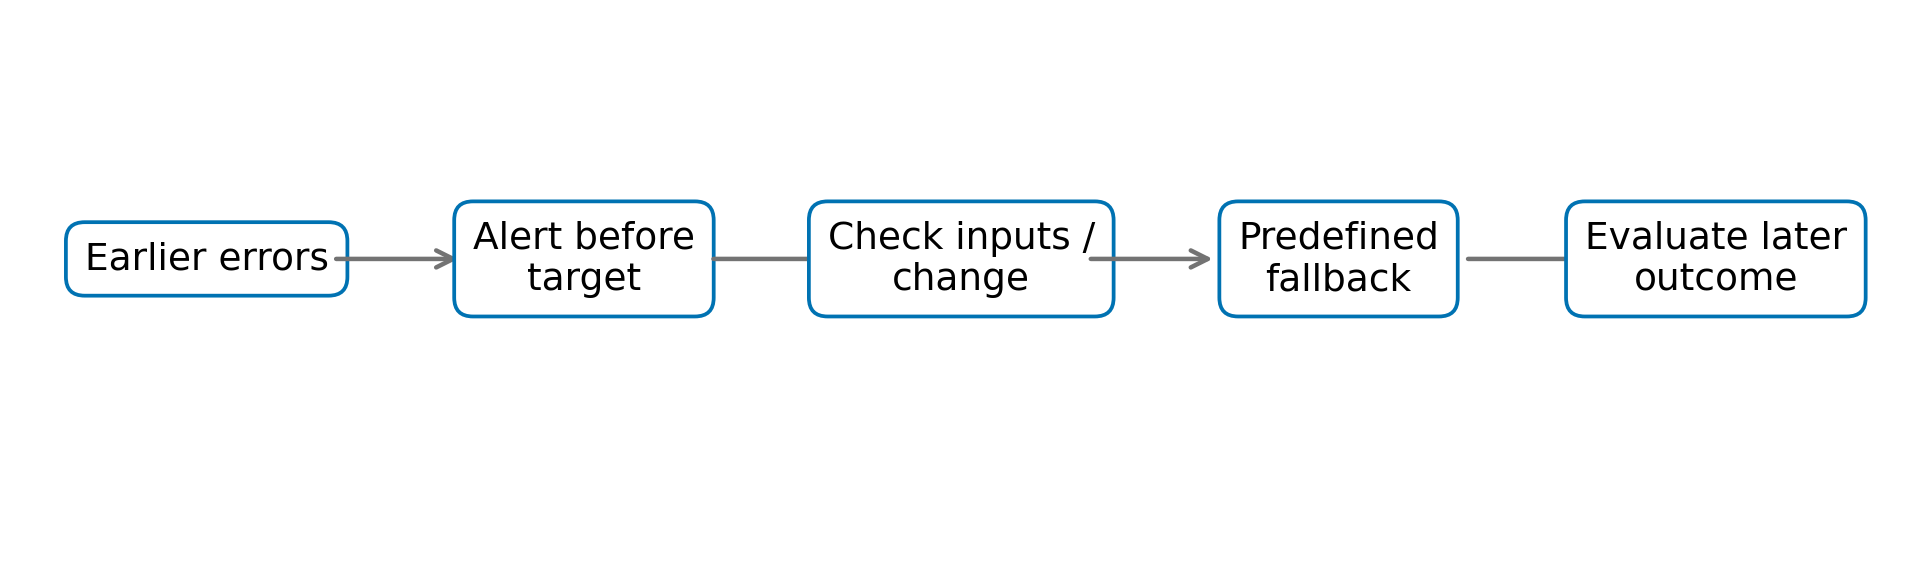

In [29]:
fig,aa=newfig();schema(aa[0],['Earlier errors','Alert before target','Check inputs / change','Predefined fallback','Evaluate later outcome'])
finish(fig,6,'A monitoring signal needs an operational response')
results['5.6']={'review_dates':int(alerts.sum()),'fallback_capacity_assumption':120,'mean_realized_policy_cost':float(alert_rows.realized_cost.mean())}

**Interpretation and limits.** Keep the 120-unit emergency capacity assumption separate from the forecast and from estimated model accuracy.

**Separate homework reference:** HW5.6; complete its marked code blanks in the separate homework notebook.

<a id="example-5-7"></a>
## 5.7 — Keep error direction and business units explicit

**Meaning.** With error defined as actual demand minus stocked quantity, a positive error is a shortage and a negative error is excess stock. The sign convention must be fixed before costs are attached.

**Worked sequence.**
1. Use actual demand 100 and candidate stock 80,100,120.
2. Subtract each action from the same actual demand.
3. Separate the positive part of the error from the positive part of its negative.
4. The shortage and excess columns contain nonnegative quantities measured in demand units.

**Expression used in the notes and slides:**

$$e=y-a$$

### 5.7.1 — Read before running

Set the three stock quantities. Subtract each from the same observed demand 100 so the error sign has one fixed meaning.

**Interpretation check:** The shortage and excess columns contain nonnegative quantities measured in demand units.

In [30]:
stock=np.array([80,100,120])
signed_error=100-stock

### 5.7.2 — Read before running

Take the positive part of actual-minus-stock for shortage and the positive part of its negative for excess. Both quantities are nonnegative and measured in demand units.

**Interpretation check:** The shortage and excess columns contain nonnegative quantities measured in demand units.

In [31]:
shortage=np.maximum(signed_error,0)
excess=np.maximum(-signed_error,0)

### 5.7.3 — Read before running

Display the computed result without refitting or changing assumptions. The shortage and excess columns contain nonnegative quantities measured in demand units.

**Interpretation check:** The shortage and excess columns contain nonnegative quantities measured in demand units.

In [32]:
print(pd.DataFrame({'stock':stock,'actual_minus_stock':signed_error,'shortage_units':shortage,'excess_units':excess}))

   stock  actual_minus_stock  shortage_units  excess_units
0     80                  20              20             0
1    100                   0               0             0
2    120                 -20               0            20


### 5.7.4 — Read before running

Draw the computed comparison: keep error direction and business units explicit. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The shortage and excess columns contain nonnegative quantities measured in demand units.

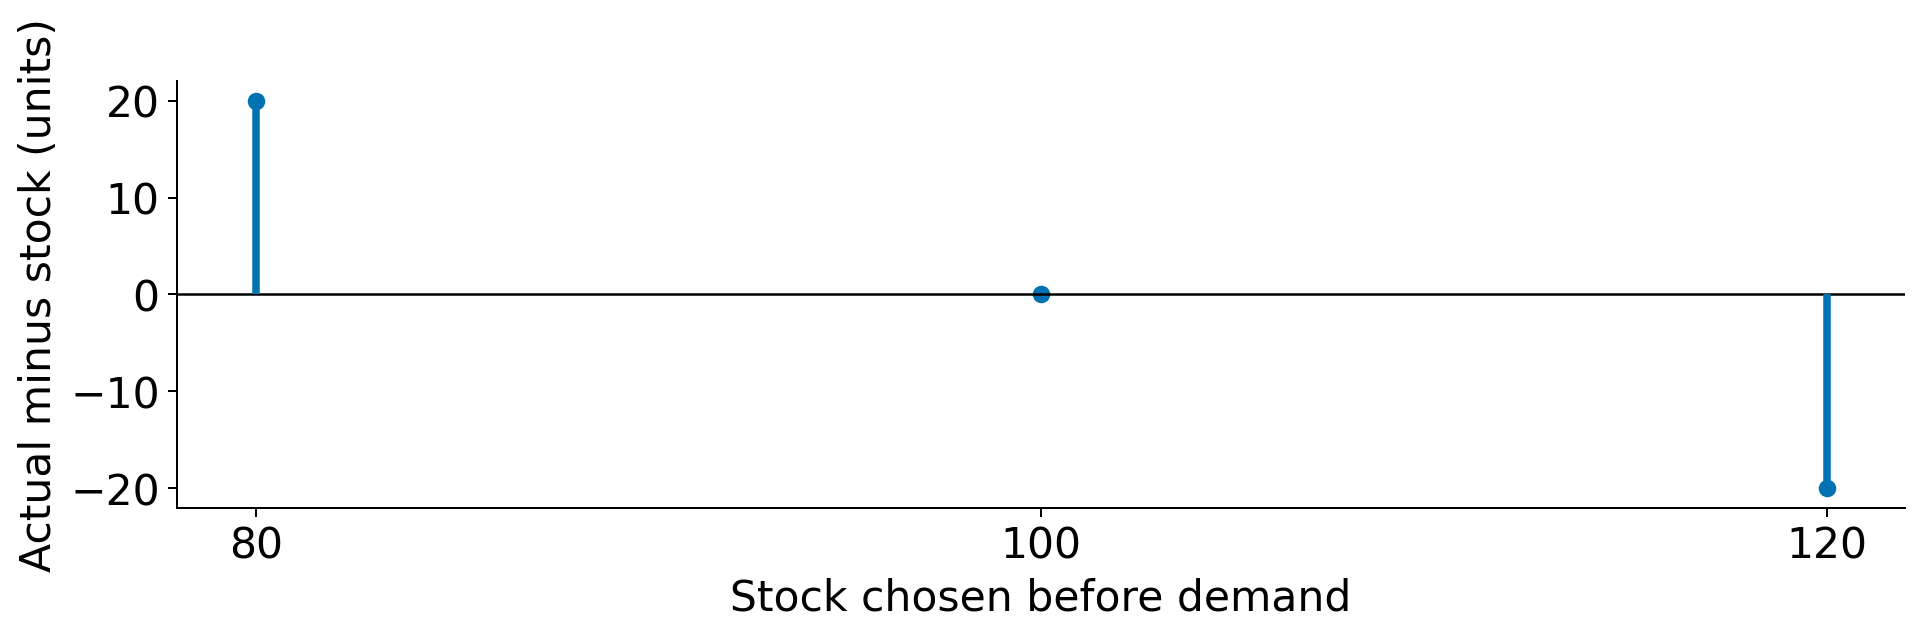

In [33]:
fig,aa=newfig();ax=aa[0];ax.axhline(0,color='black',lw=1);ax.vlines(stock,0,signed_error,color=BLUE,lw=3);ax.scatter(stock,signed_error,color=BLUE)
ax.set(xticks=stock,xlabel='Stock chosen before demand',ylabel='Actual minus stock (units)');finish(fig,7,'The error sign identifies shortage or excess')
results['5.7']={'errors':signed_error.tolist(),'shortage':shortage.tolist(),'excess':excess.tolist()}

**Interpretation and limits.** The shortage and excess columns contain nonnegative quantities measured in demand units.

**Separate homework reference:** HW5.7; complete its marked code blanks in the separate homework notebook.

<a id="example-5-8"></a>
## 5.8 — Calculate asymmetric realized loss

**Meaning.** Asymmetric loss gives different costs to shortage and excess. A cost coefficient states the cost per unit of a particular mistake; an unexplained number does not create a dollar amount.

**Worked sequence.**
1. Assume a shortage costs 3 cost units per demand unit and excess costs 1.
2. Multiply each nonnegative quantity from 5.7 by its matching coefficient.
3. Add the two cost blocks; only one is positive for a single case.
4. At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

**Expression used in the notes and slides:**

$$L(y,a)=c_u\max(y-a,0)+c_o\max(a-y,0)$$

### 5.8.1 — Read before running

State the cost per shortage unit and per excess unit separately. The coefficients are illustrative business assumptions, not fitted parameters.

**Interpretation check:** At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

In [34]:
cost_under=3.
cost_over=1.

### 5.8.2 — Read before running

Apply the specified coefficients to the nonnegative shortage and excess quantities. This evaluates each action after the outcome has been observed.

**Interpretation check:** At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

In [35]:
realized_cost=loss(100,stock,cost_under,cost_over)

### 5.8.3 — Read before running

Display the computed result without refitting or changing assumptions. At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

**Interpretation check:** At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

In [36]:
print(pd.DataFrame({'stock':stock,'realized_cost':realized_cost}))

   stock  realized_cost
0     80           60.0
1    100            0.0
2    120           20.0


### 5.8.4 — Read before running

Draw the computed comparison: calculate asymmetric realized loss. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

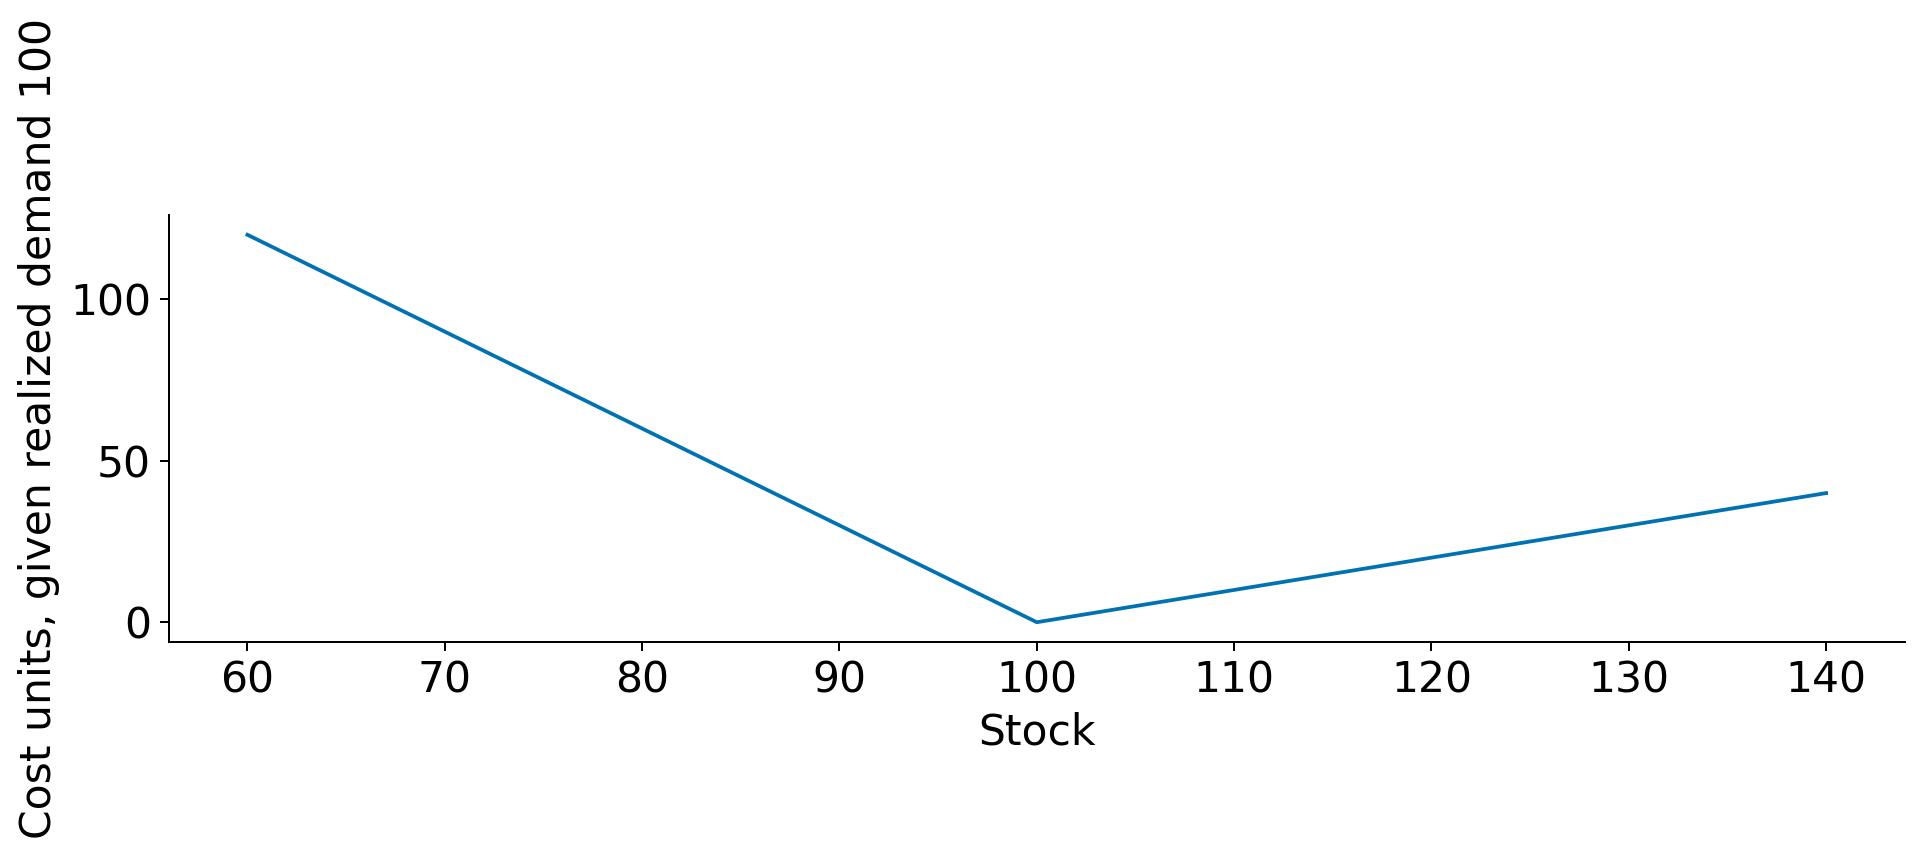

In [37]:
loss_grid=np.arange(60,141);fig,aa=newfig();aa[0].plot(loss_grid,loss(100,loss_grid),color=BLUE)
aa[0].set(xlabel='Stock',ylabel='Cost units, given realized demand 100');finish(fig,8,'Different slopes represent different error costs')
results['5.8']={'costs':realized_cost.tolist(),'under_cost':3,'over_cost':1}

**Interpretation and limits.** At realized demand 100, stock 80 costs 60 and stock 120 costs 20; this is hindsight loss, not an oracle for choosing tomorrow's action.

**Separate homework reference:** HW5.8; complete its marked code blanks in the separate homework notebook.

<a id="example-5-9"></a>
## 5.9 — Choose using expected loss before seeing demand

**Meaning.** A probability distribution assigns probability to possible outcomes. Expected loss is a probability-weighted average of the losses an action would produce across those outcomes.

**Worked sequence.**
1. Assume demand outcomes 80,100,140 with probabilities .2,.5,.3. These probabilities are stated teaching assumptions.
2. Evaluate each candidate stock against every possible demand.
3. Multiply each loss by its outcome probability and add across outcomes.
4. Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

**Expression used in the notes and slides:**

$$\mathbb{E}[L(Y,a)]=\sum_j p_jL(y_j,a)$$

### 5.9.1 — Read before running

Define three possible demand outcomes and their assumed probabilities. The outcome is unknown when the action is selected; probabilities sum to one.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

In [38]:
demand_cases=np.array([80,100,140])
probabilities=np.array([.2,.5,.3])

### 5.9.2 — Read before running

Evaluate every candidate against every possible demand outcome. Rows index actions and columns index outcomes, so the cost matrix retains all consequences.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

In [39]:
candidate_stock=np.array([80,100,140])
loss_matrix=loss(demand_cases[None,:],candidate_stock[:,None])

### 5.9.3 — Read before running

Multiply each outcome column by its probability and add across outcomes. The resulting vector contains one expected cost per candidate action.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

In [40]:
expected_loss=loss_matrix@probabilities

### 5.9.4 — Read before running

Display the computed result without refitting or changing assumptions. Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

In [41]:
print(pd.DataFrame(loss_matrix,index=candidate_stock,columns=demand_cases))

      80    100    140
80    0.0  60.0  180.0
100  20.0   0.0  120.0
140  60.0  40.0    0.0


### 5.9.5 — Read before running

Display the computed result without refitting or changing assumptions. Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

In [42]:
print('Expected losses:',expected_loss)

Expected losses: [84. 40. 32.]


### 5.9.6 — Read before running

Draw the computed comparison: choose using expected loss before seeing demand. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

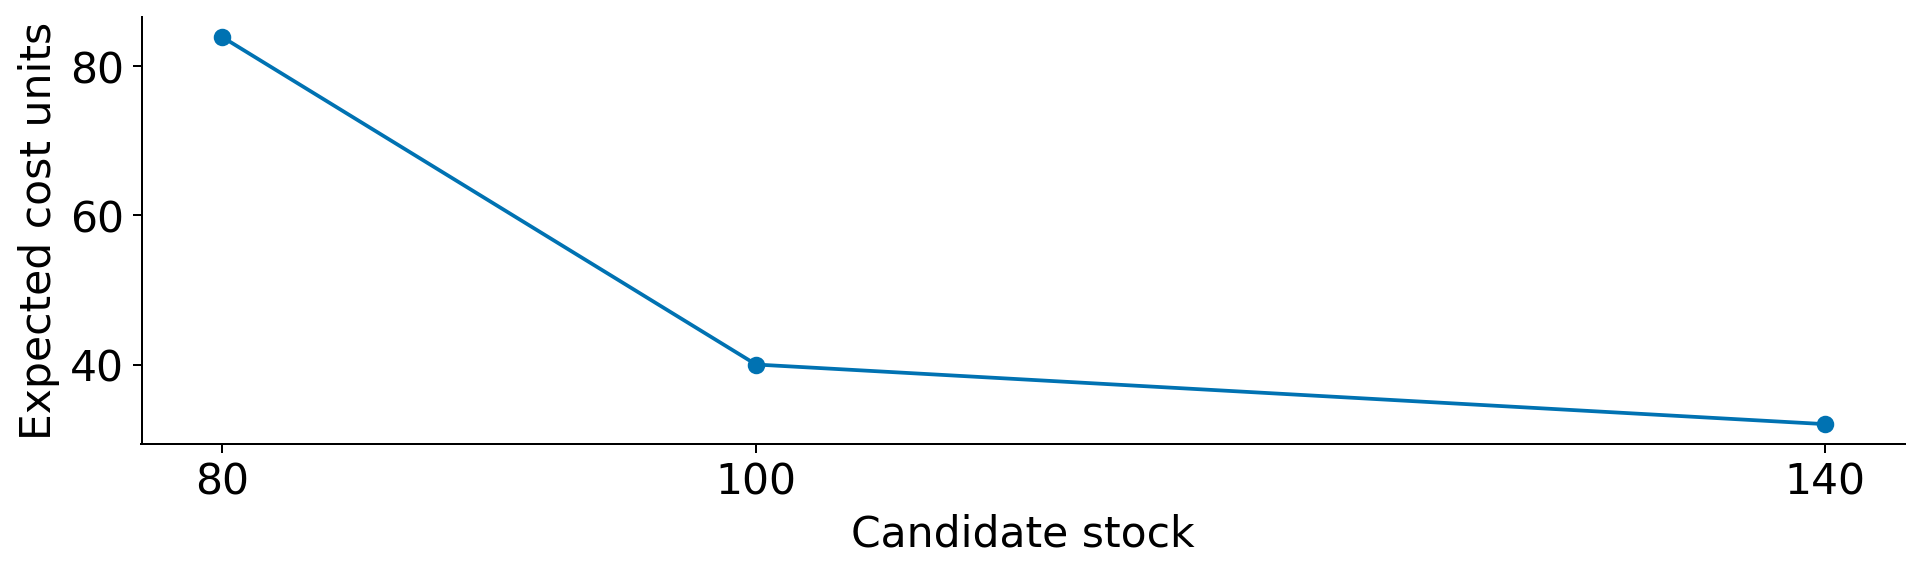

In [43]:
fig,aa=newfig();aa[0].plot(candidate_stock,expected_loss,'o-',color=BLUE);aa[0].set(xticks=candidate_stock,xlabel='Candidate stock',ylabel='Expected cost units')
finish(fig,9,'Weight each possible consequence before choosing')
results['5.9']={'demands':demand_cases.tolist(),'probabilities':probabilities.tolist(),'expected_losses':expected_loss.tolist(),'mean_demand':float(demand_cases@probabilities)}

**Interpretation and limits.** Among stock 80,100,140, expected costs are 84,40,32; choosing 140 follows the assumed costs and probabilities.

**Separate homework reference:** HW5.9; complete its marked code blanks in the separate homework notebook.

<a id="example-5-10"></a>
## 5.10 — Read a quantile from cumulative probability

**Meaning.** A cumulative probability adds the probabilities of outcomes at or below a cutoff. A quantile at level tau is a cutoff reaching that cumulative probability; for this discrete example use the smallest outcome whose cumulative probability is at least tau.

**Worked sequence.**
1. Sort the three demand outcomes from low to high.
2. Accumulate their probabilities to .2,.7,1.0.
3. The median is the .5 quantile, equal to 100.
4. The .75 quantile is 140 because the cumulative probability at 100 is only .7.

### 5.10.1 — Read before running

Add probabilities in sorted demand order, then define the smallest-cutoff quantile lookup. The function returns a demand value, not a probability.

**Interpretation check:** The .75 quantile is 140 because the cumulative probability at 100 is only .7.

In [44]:
cumulative_probability=np.cumsum(probabilities)
def demand_quantile(tau):return float(demand_cases[np.searchsorted(cumulative_probability,tau,side='left')])

### 5.10.2 — Read before running

Display the computed result without refitting or changing assumptions. The .75 quantile is 140 because the cumulative probability at 100 is only .7.

**Interpretation check:** The .75 quantile is 140 because the cumulative probability at 100 is only .7.

In [45]:
print('CDF:',cumulative_probability,'Median:',demand_quantile(.5),'75% quantile:',demand_quantile(.75))

CDF: [0.2 0.7 1. ] Median: 100.0 75% quantile: 140.0


### 5.10.3 — Read before running

Draw the computed comparison: read a quantile from cumulative probability. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The .75 quantile is 140 because the cumulative probability at 100 is only .7.

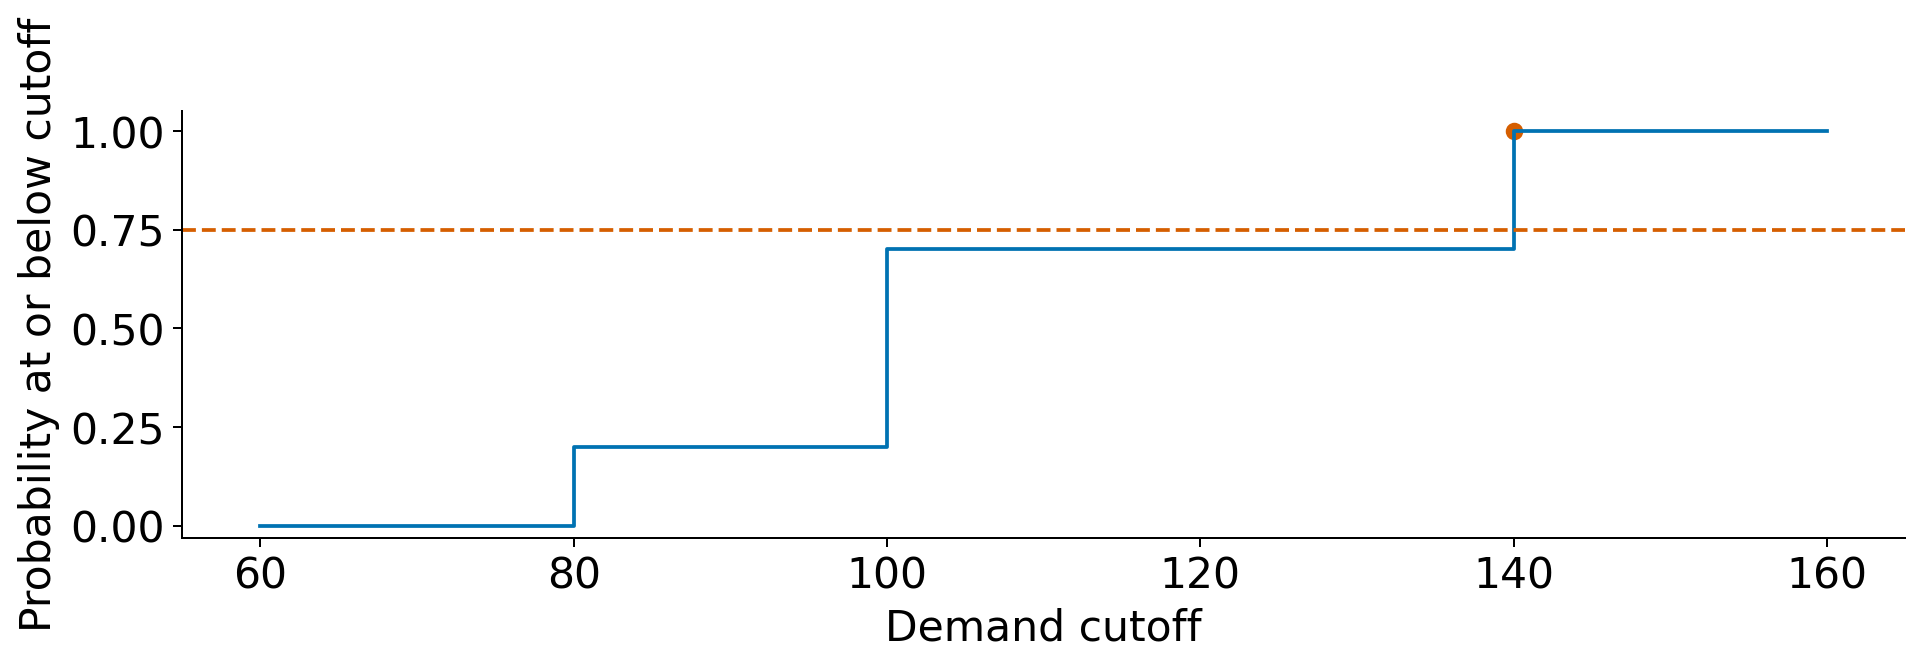

In [46]:
fig,aa=newfig();ax=aa[0];ax.step(np.r_[60,demand_cases,160],np.r_[0,cumulative_probability,1],where='post',color=BLUE)
ax.axhline(.75,color=ORANGE,ls='--');ax.scatter([140],[1],color=ORANGE);ax.set(xlabel='Demand cutoff',ylabel='Probability at or below cutoff',ylim=(-.03,1.05));finish(fig,10,'The 75% cutoff must pass cumulative probability 0.75')
results['5.10']={'cdf':cumulative_probability.tolist(),'median':demand_quantile(.5),'q75':demand_quantile(.75)}

**Interpretation and limits.** The .75 quantile is 140 because the cumulative probability at 100 is only .7.

**Separate homework reference:** HW5.10; complete its marked code blanks in the separate homework notebook.

<a id="example-5-11"></a>
## 5.11 — Derive the cost-implied quantile direction

**Meaning.** For positive linear shortage and excess costs without additional constraints, a cost-minimizing action is a quantile at level shortage cost divided by the sum of shortage and excess costs. Discrete distributions can have several minimizing actions at a boundary.

**Worked sequence.**
1. The numerator is the cost of being below demand, not the cost of being above it.
2. Divide shortage cost 3 by total cost weight 4 to obtain .75.
3. Reverse the costs to shortage 1 and excess 3; the quantile level becomes .25.
4. Read the corresponding actions from the same demand distribution: 140 and 100.

**Expression used in the notes and slides:**

$$\tau^*=\frac{c_u}{c_u+c_o}$$

### 5.11.1 — Read before running

Specify three shortage/excess cost pairs while keeping the demand distribution fixed. Prepare one result row for each pair.

**Interpretation check:** Read the corresponding actions from the same demand distribution: 140 and 100.

In [47]:
cost_pairs=[(1,1),(3,1),(1,3)]
quantile_actions=[]

### 5.11.2 — Read before running

For each cost pair, divide shortage cost by total cost weight, then look up the corresponding quantile in the unchanged demand distribution.

**Interpretation check:** Read the corresponding actions from the same demand distribution: 140 and 100.

In [48]:
for cu,co in cost_pairs:
    tau=cu/(cu+co);quantile_actions.append({'shortage_cost':cu,'excess_cost':co,'tau':tau,'action':demand_quantile(tau)})

### 5.11.3 — Read before running

Display the computed result without refitting or changing assumptions. Read the corresponding actions from the same demand distribution: 140 and 100.

**Interpretation check:** Read the corresponding actions from the same demand distribution: 140 and 100.

In [49]:
print(pd.DataFrame(quantile_actions))

   shortage_cost  excess_cost   tau  action
0              1            1  0.50   100.0
1              3            1  0.75   140.0
2              1            3  0.25   100.0


### 5.11.4 — Read before running

Draw the computed comparison: derive the cost-implied quantile direction. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Read the corresponding actions from the same demand distribution: 140 and 100.

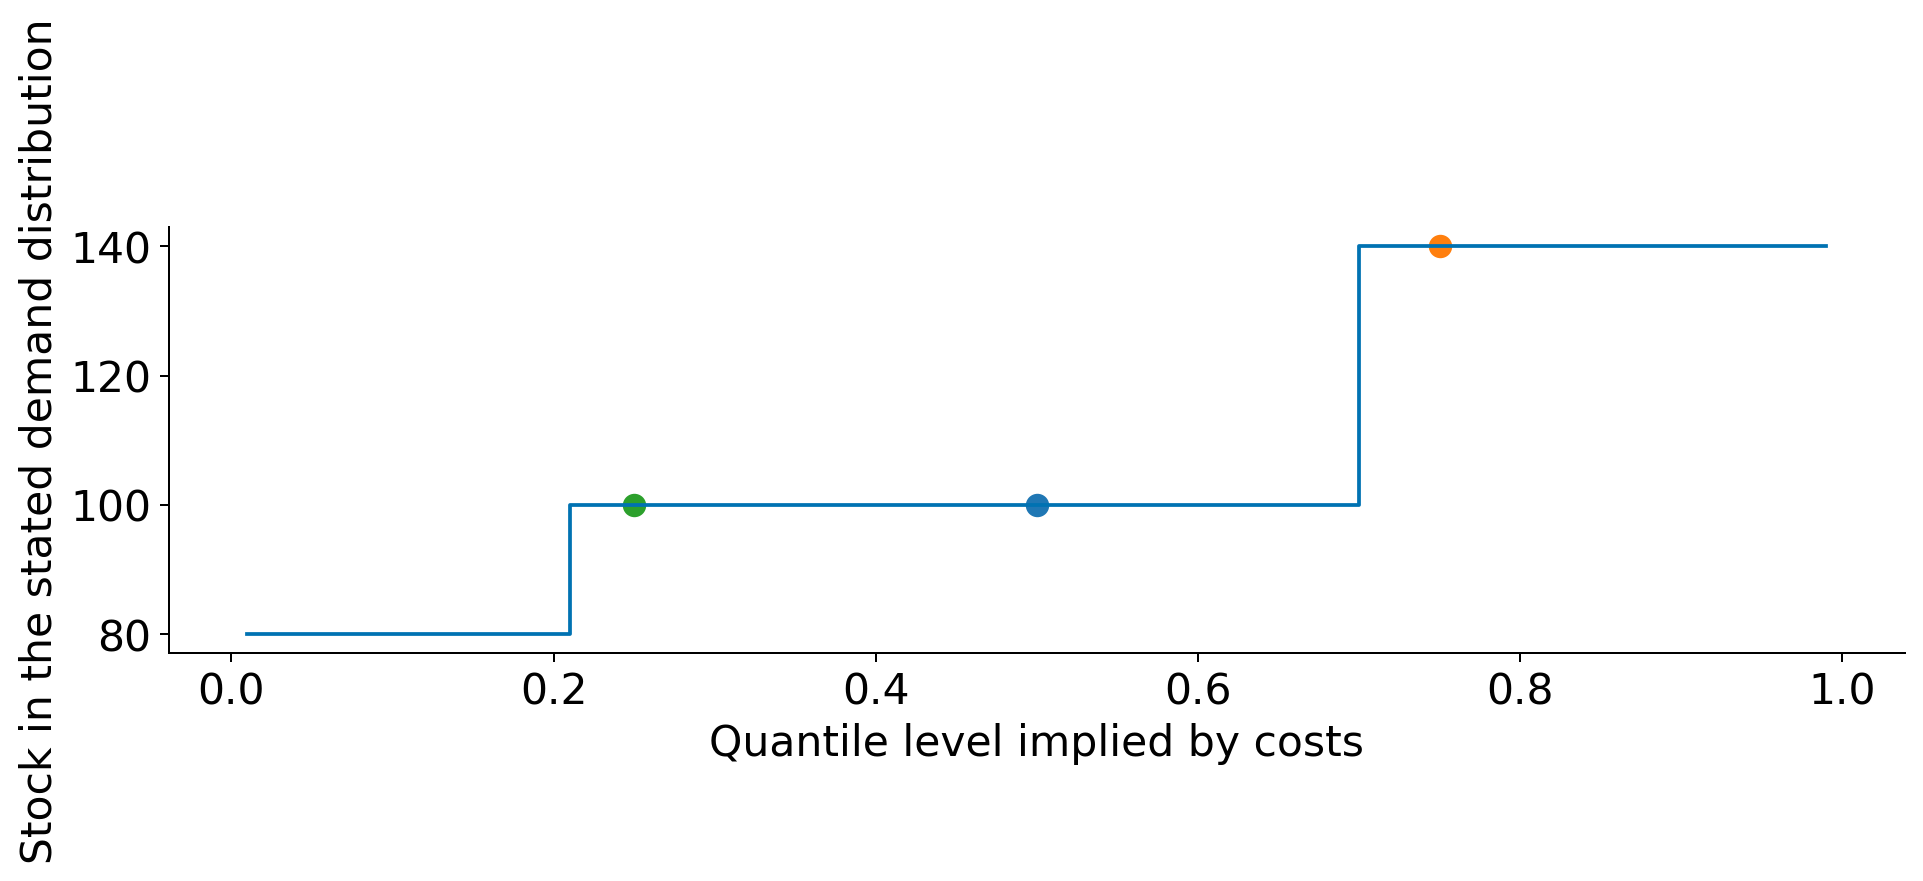

In [50]:
fig,aa=newfig();ax=aa[0];tau_grid=np.linspace(.01,.99,99);ax.step(tau_grid,[demand_quantile(t) for t in tau_grid],where='post',color=BLUE)
for r in quantile_actions:ax.scatter(r['tau'],r['action'],s=70)
ax.set(xlabel='Quantile level implied by costs',ylabel='Stock in the stated demand distribution');finish(fig,11,'Costly shortage moves the chosen quantile upward')
results['5.11']={'policies':quantile_actions}

**Interpretation and limits.** Read the corresponding actions from the same demand distribution: 140 and 100.

**Separate homework reference:** HW5.11; complete its marked code blanks in the separate homework notebook.

<a id="example-5-12"></a>
## 5.12 — Impose a feasible action set

**Meaning.** A constraint restricts the actions available. The best feasible action minimizes the same expected loss over the allowed set; an unconstrained optimum is not automatically implementable.

**Worked sequence.**
1. Retain the .75 quantile rule and the three-outcome distribution.
2. Impose a stated capacity of 120 units.
3. Compute expected loss for every integer stock from 60 to 120.
4. The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

### 5.12.1 — Read before running

Restrict candidate stock to the integers 60 through 120. Evaluate expected cost on this feasible grid using the original probability weights.

**Interpretation check:** The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

In [51]:
feasible_stock=np.arange(60,121)
feasible_expected=loss(demand_cases[None,:],feasible_stock[:,None])@probabilities

### 5.12.2 — Read before running

Find the index of the smallest expected cost and map that index back to its feasible stock value. An array index is not itself a stock quantity.

**Interpretation check:** The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

In [52]:
best_feasible=int(feasible_stock[np.argmin(feasible_expected)])

### 5.12.3 — Read before running

Display the computed result without refitting or changing assumptions. The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

**Interpretation check:** The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

In [53]:
print('Feasible action and expected cost:',best_feasible,feasible_expected.min())

Feasible action and expected cost: 120 36.0


### 5.12.4 — Read before running

Draw the computed comparison: impose a feasible action set. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

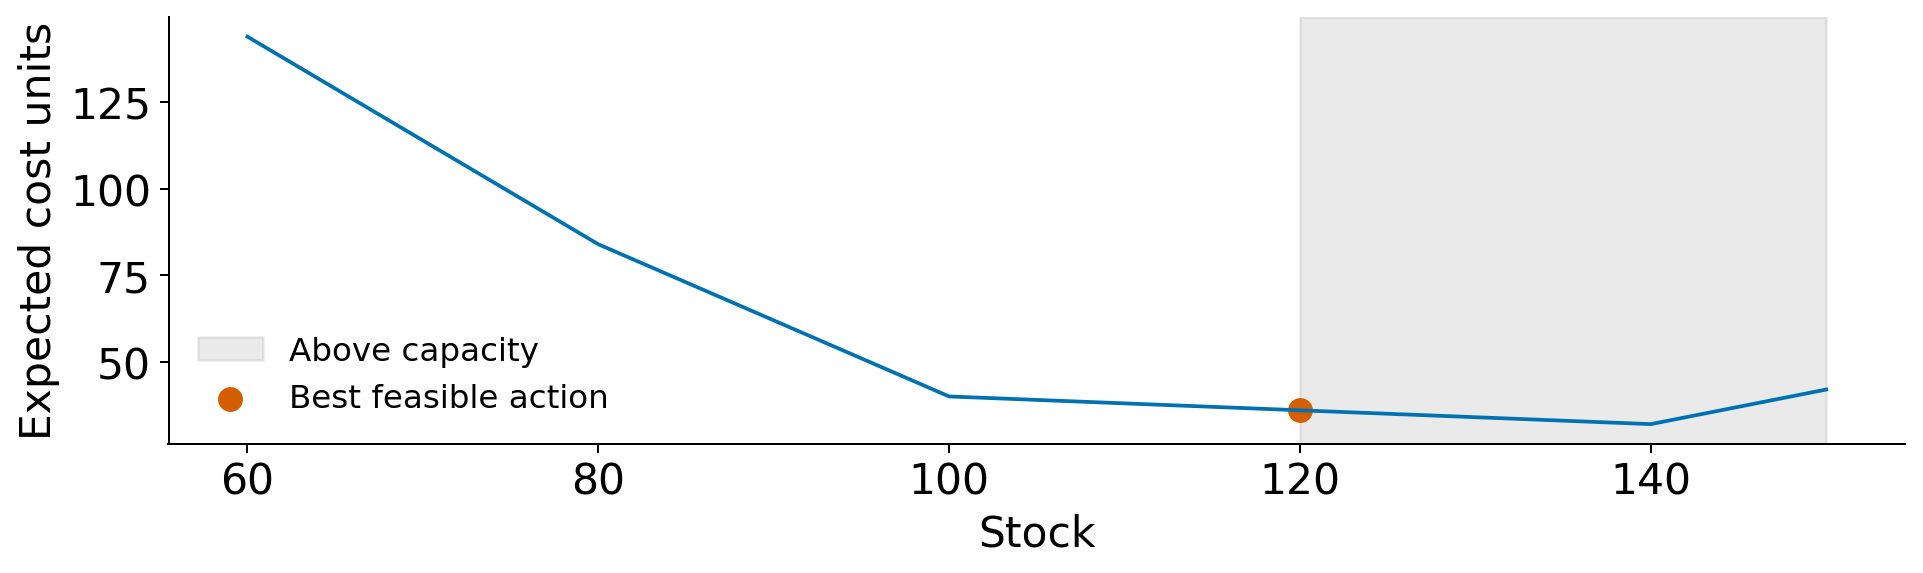

In [54]:
fig,aa=newfig();all_stock=np.arange(60,151);ax=aa[0];ax.plot(all_stock,loss(demand_cases[None,:],all_stock[:,None])@probabilities,color=BLUE)
ax.axvspan(120,150,color=GRAY,alpha=.15,label='Above capacity');ax.scatter([120],[36],color=ORANGE,s=80,label='Best feasible action');ax.set(xlabel='Stock',ylabel='Expected cost units');ax.legend(fontsize=13)
finish(fig,12,'A recommendation must respect capacity')
results['5.12']={'capacity':120,'best_feasible':best_feasible,'expected_cost':float(feasible_expected.min())}

**Interpretation and limits.** The best feasible stock is 120 with expected cost 36; the unconstrained 140-unit action is infeasible.

**Separate homework reference:** HW5.12; complete its marked code blanks in the separate homework notebook.

<a id="example-5-13"></a>
## 5.13 — Separate prediction accuracy from decision loss

**Meaning.** Forecast accuracy measures closeness to outcomes under a specified error score. Business loss evaluates the consequence of the action. A lower symmetric error score need not imply lower asymmetric cost.

**Worked sequence.**
1. For this constructed comparison only, let each rule stock its own constant point forecast, 100 or 120, on the same outcomes 80,100,140.
2. Compare constant actions 100 and 120.
3. MAE prefers 100: 20 versus about 26.67.
4. With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

### 5.13.1 — Read before running

For this comparison only, each rule stocks its constant point forecast. Score the same three equally weighted realized outcomes under MAE and the 3:1 business loss.

**Interpretation check:** With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

In [55]:
comparison_rows=[]
for action in [100,120]:comparison_rows.append({'action':action,'MAE':metrics(demand_cases,np.full(3,action))['MAE'],'mean_business_loss':float(loss(demand_cases,action).mean())})

### 5.13.2 — Read before running

Arrange the two scoring results in a labeled table. Each column answers a different question; compare rankings without mixing the units.

**Interpretation check:** With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

In [56]:
score_comparison=pd.DataFrame(comparison_rows)

### 5.13.3 — Read before running

Display the computed result without refitting or changing assumptions. With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

**Interpretation check:** With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

In [57]:
print(score_comparison)

   action        MAE  mean_business_loss
0     100  20.000000           46.666667
1     120  26.666667           40.000000


### 5.13.4 — Read before running

Draw the computed comparison: separate prediction accuracy from decision loss. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

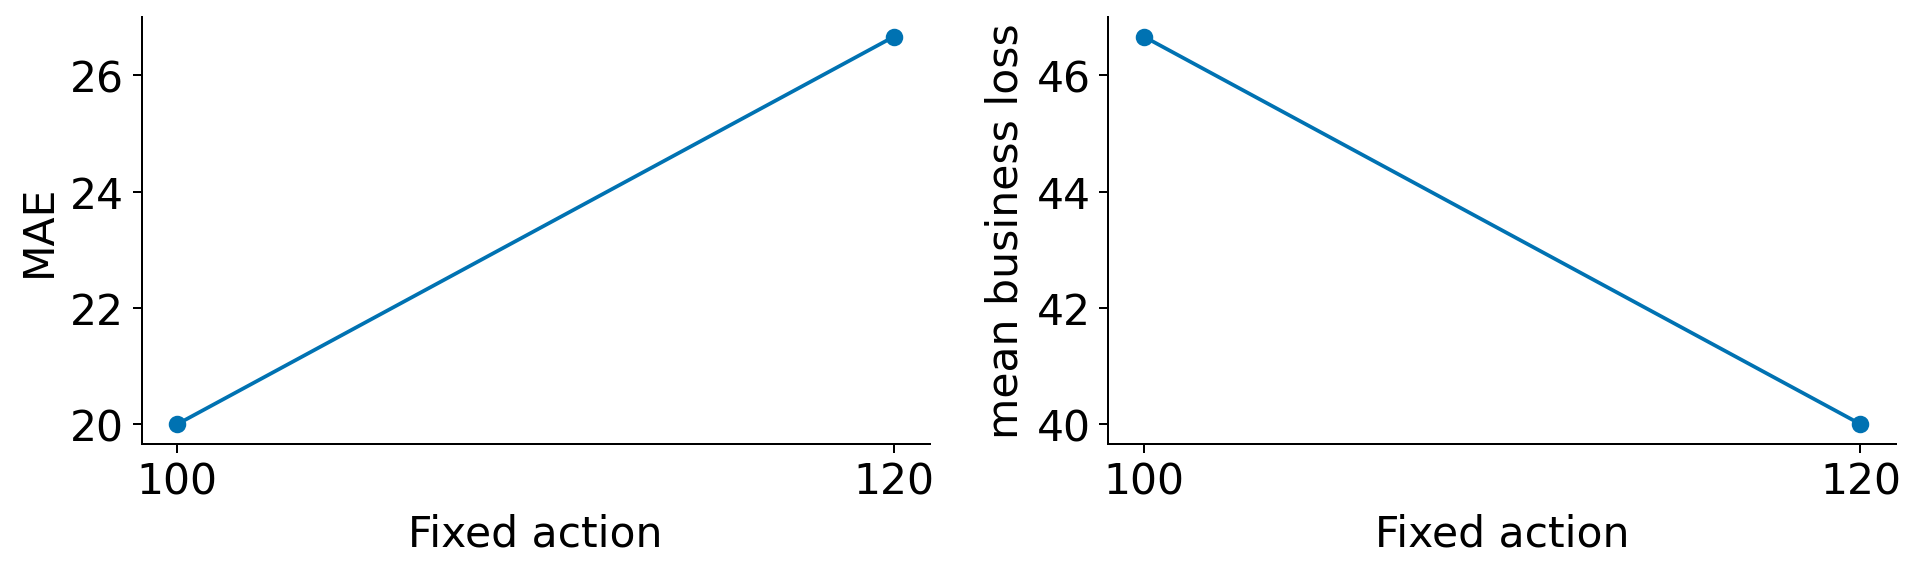

In [58]:
fig,aa=newfig(2)
for ax,column in zip(aa,['MAE','mean_business_loss']):ax.plot(score_comparison.action,score_comparison[column],'o-',color=BLUE);ax.set(xticks=[100,120],xlabel='Fixed action',ylabel=column.replace('_',' '))
finish(fig,13,'Different loss functions can rank the same rules differently')
results['5.13']={'comparison':comparison_rows}

**Interpretation and limits.** With shortage cost 3 and excess cost 1, average realized cost prefers 120: about 40 versus 46.67. These three equally weighted realized cases are separate from the weighted distribution in 5.9.

**Separate homework reference:** HW5.13; complete its marked code blanks in the separate homework notebook.

<a id="example-5-14"></a>
## 5.14 — Reuse the classroom data with an honest chronology

**Meaning.** A calibration block contains outcomes from earlier forecasts made without those outcomes. It can estimate an error distribution for a fixed prediction procedure. Reusing a previously inspected teaching dataset does not create a new unseen test.

**Worked sequence.**
1. Load the same seed-417 classroom demand file used in Lecture 4.
2. Create two known lag inputs; 178 rows remain after the first two dates.
3. Use 124 training rows, 27 calibration rows and 27 later assessment rows.
4. Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

### 5.14.1 — Read before running

Load the same local, dated demand simulation as Lecture 4 and create the one-day lag. Earlier demand becomes an input; current demand remains the target.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [59]:
demand=pd.read_csv(HERE/'business_demand.csv',parse_dates=['date']).set_index('date').sort_index()
demand['lag_demand']=demand.demand.shift(1)

### 5.14.2 — Read before running

Create the two-day lag and remove only rows lacking the required earlier inputs. Both lag columns must be available before the corresponding target.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [60]:
demand['lag_demand_2']=demand.demand.shift(2)
frame=demand.dropna().copy()

### 5.14.3 — Read before running

Name the two input columns and preserve chronological order when assigning 124 training, 27 calibration and 27 assessment rows.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [61]:
features=['lag_demand','lag_demand_2']
train,cal,assessment=frame.iloc[:124],frame.iloc[124:151],frame.iloc[151:]

### 5.14.4 — Read before running

Fit the linear baseline and its input scaler on training only. This stored model remains unchanged when calibration errors and later forecasts are generated.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [62]:
point_model=make_pipeline(StandardScaler(),LinearRegression()).fit(train[features],train.demand)

### 5.14.5 — Read before running

Predict on the later calibration block with the stored model, then subtract these predictions from observed calibration demand. These errors did not help fit the model.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [63]:
cal_point=point_model.predict(cal[features])
cal_error=cal.demand.to_numpy()-cal_point

### 5.14.6 — Read before running

Save point forecasts for the still later assessment dates using exactly the same fitted procedure.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [64]:
assessment_point=point_model.predict(assessment[features])

### 5.14.7 — Read before running

Display the computed result without refitting or changing assumptions. Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [65]:
print('Rows:',len(train),len(cal),len(assessment))

Rows: 124 27 27


### 5.14.8 — Read before running

Display the computed result without refitting or changing assumptions. Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

In [66]:
print('Calibration RMSE:',metrics(cal.demand,cal_point)['RMSE'])

Calibration RMSE: 20.617410860186716


### 5.14.9 — Read before running

Draw the computed comparison: reuse the classroom data with an honest chronology. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

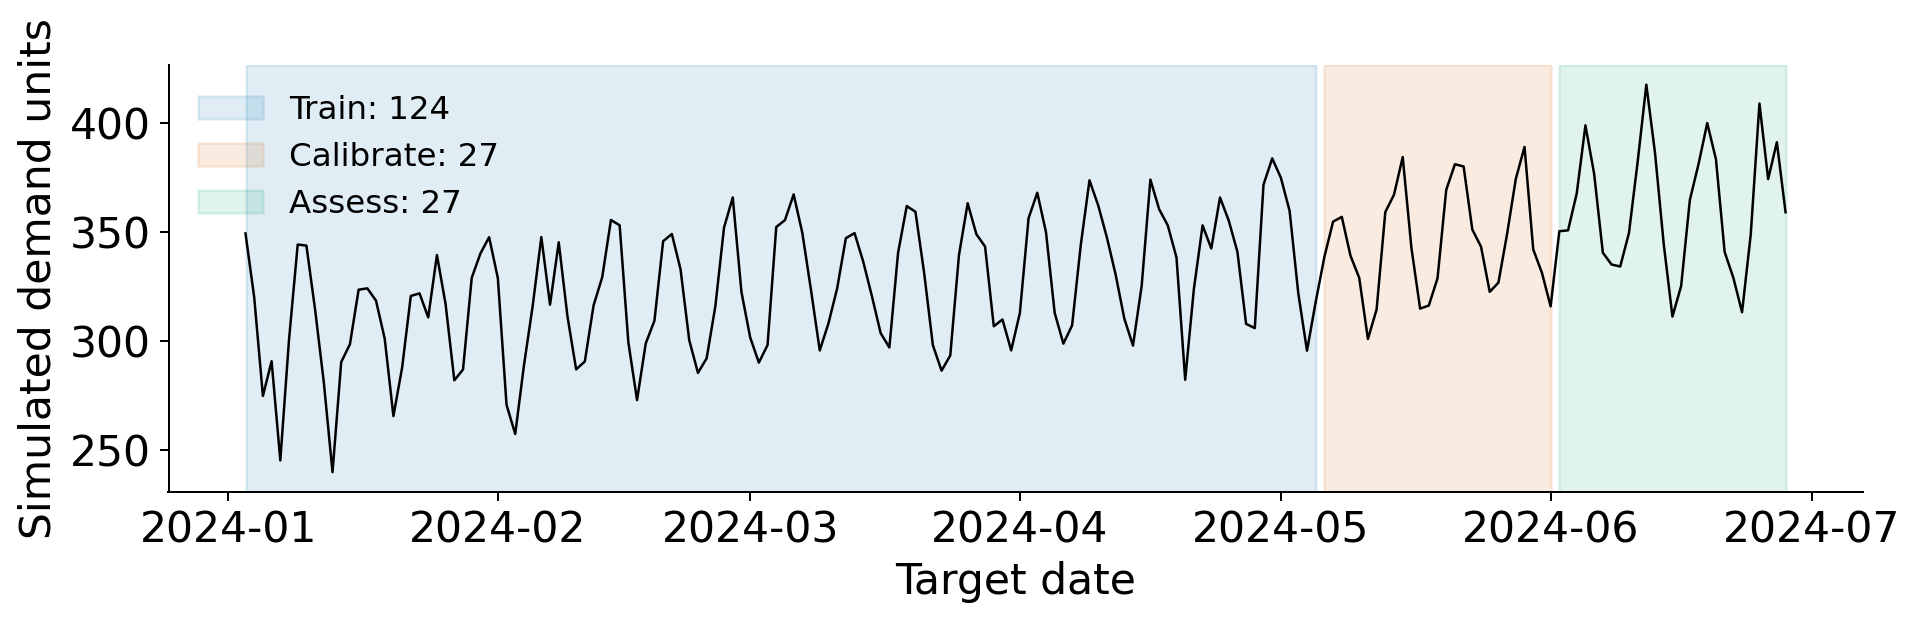

In [67]:
fig,aa=newfig();ax=aa[0];ax.plot(frame.index,frame.demand,color='black',lw=1)
for block,col,label in [(train,BLUE,'Train: 124'),(cal,ORANGE,'Calibrate: 27'),(assessment,GREEN,'Assess: 27')]:ax.axvspan(block.index[0],block.index[-1],color=col,alpha=.12,label=label)
ax.set(xlabel='Target date',ylabel='Simulated demand units');ax.legend(fontsize=13);finish(fig,14,'Same teaching history, separate fitting and calibration roles')
results['5.14']={'rows':[len(train),len(cal),len(assessment)],'calibration_RMSE':metrics(cal.demand,cal_point)['RMSE'],'data_source':'Same local classroom simulation, seed 417; previously inspected teaching data'}

**Interpretation and limits.** Fit the linear baseline on training only. Keep it fixed during calibration and assessment; unlike Lecture 4's final refit, do not change the model after calibrating its errors.

**Separate homework reference:** HW5.14; complete its marked code blanks in the separate homework notebook.

<a id="example-5-15"></a>
## 5.15 — Distinguish training residuals from later forecast errors

**Meaning.** A training residual uses an outcome that helped fit the rule. A later forecast error compares an outcome with a prediction made before seeing that outcome. Their spreads can differ; neither spread is guaranteed to describe a changed future.

**Worked sequence.**
1. Fit the specified 100-tree forest on the same 124 training rows.
2. Compute its training residuals and its errors on the 27 calibration dates.
3. Compare the mean absolute error and the 90th percentile of absolute error.
4. Read the measured values; do not assume the ratio or claim a universal size of optimism.

### 5.15.1 — Read before running

Fit the specified forest on training only and compute its training residuals. Its fixed settings match the Lecture 4 forest demonstration.

**Interpretation check:** Read the measured values; do not assume the ratio or claim a universal size of optimism.

In [68]:
forest=RandomForestRegressor(n_estimators=100,max_depth=5,min_samples_leaf=8,max_features=1,random_state=417,n_jobs=1).fit(train[features],train.demand)
forest_training_error=train.demand.to_numpy()-forest.predict(train[features])

### 5.15.2 — Read before running

Predict calibration demand using the stored forest. Compare the two error roles using actual measured MAE and absolute-error quantiles, retaining their different sample sizes.

**Interpretation check:** Read the measured values; do not assume the ratio or claim a universal size of optimism.

In [69]:
forest_cal_error=cal.demand.to_numpy()-forest.predict(cal[features])
residual_summary=pd.DataFrame([{'sample':name,'n':len(e),'MAE':float(np.abs(e).mean()),'absolute_q90':float(np.quantile(np.abs(e),.9))} for name,e in [('Training',forest_training_error),('Calibration',forest_cal_error)]])

### 5.15.3 — Read before running

Display the computed result without refitting or changing assumptions. Read the measured values; do not assume the ratio or claim a universal size of optimism.

**Interpretation check:** Read the measured values; do not assume the ratio or claim a universal size of optimism.

In [70]:
print(residual_summary)

        sample    n        MAE  absolute_q90
0     Training  124  14.651651     30.869693
1  Calibration   27  18.308242     38.571733


### 5.15.4 — Read before running

Draw the computed comparison: distinguish training residuals from later forecast errors. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Read the measured values; do not assume the ratio or claim a universal size of optimism.

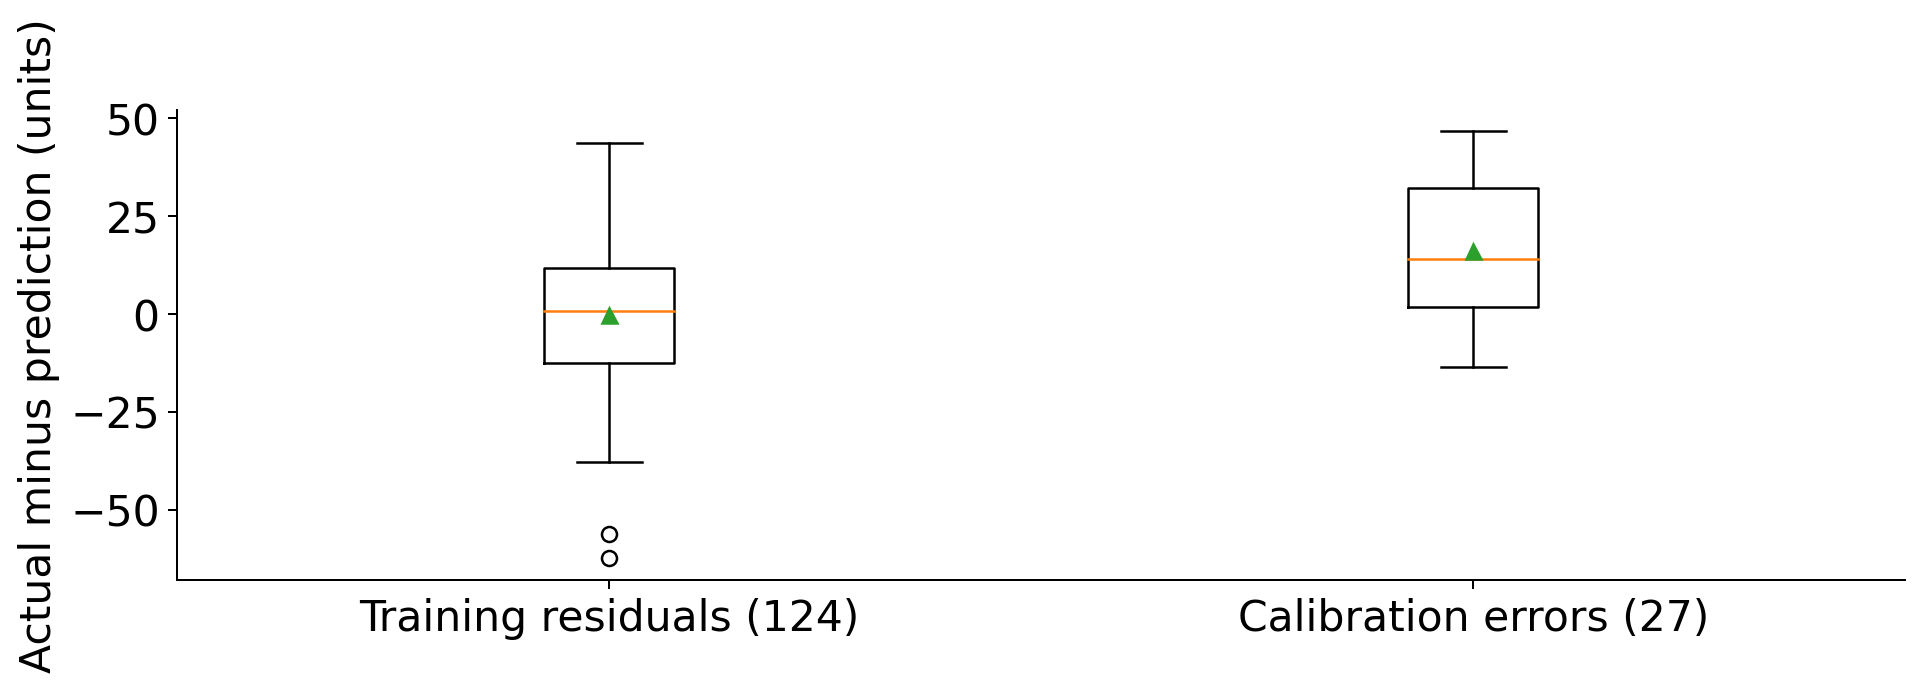

In [71]:
fig,aa=newfig();ax=aa[0];ax.boxplot([forest_training_error,forest_cal_error],labels=['Training residuals (124)','Calibration errors (27)'],showmeans=True)
ax.set(ylabel='Actual minus prediction (units)');finish(fig,15,'Compare errors from different information roles')
results['5.15']={'summary':residual_summary.to_dict('records')}

**Interpretation and limits.** Read the measured values; do not assume the ratio or claim a universal size of optimism.

**Separate homework reference:** HW5.15; complete its marked code blanks in the separate homework notebook.

<a id="example-5-16"></a>
## 5.16 — Construct an empirical prediction interval

**Meaning.** A prediction interval gives lower and upper outcome bounds from a stated forecasting procedure. An empirical error quantile is a cutoff estimated from recorded errors. A constant pair of error offsets creates constant-width bands, not state-dependent widening. Nominal coverage is the intended inclusion rate of the procedure; its measured inclusion rate must be checked on outcomes.

**Worked sequence.**
1. Use the fixed linear model's 27 calibration errors.
2. For an 80% central interval take the .10 and .90 empirical error quantiles; use NumPy linear interpolation consistently.
3. Add each offset to each later point forecast.
4. For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

**Expression used in the notes and slides:**

$$[\ell_t,u_t]=[\hat y_{t\mid t-1}+\hat q_{\alpha/2},\ \hat y_{t\mid t-1}+\hat q_{1-\alpha/2}]$$

### 5.16.1 — Read before running

Read .10/.90 and .025/.975 cutoffs from the same 27 linear-model calibration errors. Linear interpolation is the stated numerical quantile convention.

**Interpretation check:** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

In [72]:
q80=np.quantile(cal_error,[.1,.9],method='linear')
q95=np.quantile(cal_error,[.025,.975],method='linear')

### 5.16.2 — Read before running

Add the two 80% error offsets separately to each saved assessment point forecast. One offset is used for the lower bound and the other for the upper bound.

**Interpretation check:** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

In [73]:
lo80=assessment_point+q80[0]
hi80=assessment_point+q80[1]

### 5.16.3 — Read before running

Apply the corresponding 95% offsets to the same centers. Their constant difference creates a constant width across dates.

**Interpretation check:** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

In [74]:
lo95=assessment_point+q95[0]
hi95=assessment_point+q95[1]

### 5.16.4 — Read before running

Display the computed result without refitting or changing assumptions. For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

**Interpretation check:** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

In [75]:
print('80% offsets:',q80,'95% offsets:',q95)

80% offsets: [-7.1783067  33.20710347] 95% offsets: [-14.69718643  39.12289477]


### 5.16.5 — Read before running

Draw the computed comparison: construct an empirical prediction interval. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

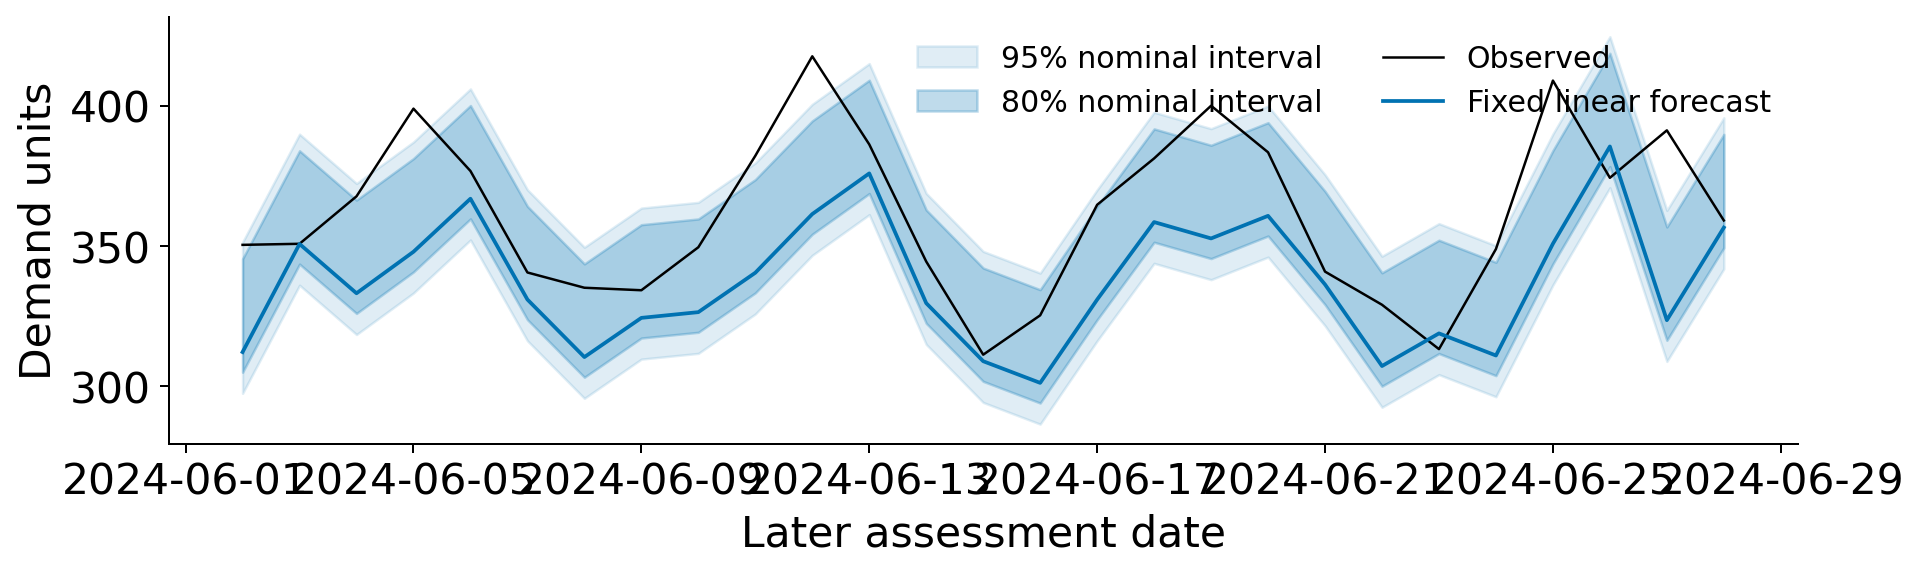

In [76]:
fig,aa=newfig();ax=aa[0];ax.fill_between(assessment.index,lo95,hi95,color=BLUE,alpha=.12,label='95% nominal interval');ax.fill_between(assessment.index,lo80,hi80,color=BLUE,alpha=.25,label='80% nominal interval')
ax.plot(assessment.index,assessment.demand,color='black',lw=1,label='Observed');ax.plot(assessment.index,assessment_point,color=BLUE,label='Fixed linear forecast');ax.set(xlabel='Later assessment date',ylabel='Demand units');ax.legend(fontsize=12,ncol=2)
finish(fig,16,'Fixed error offsets make constant-width bands')
results['5.16']={'q80_offsets':q80.tolist(),'q95_offsets':q95.tolist(),'width80':float(q80[1]-q80[0]),'width95':float(q95[1]-q95[0])}

**Interpretation and limits.** For a 95% interval use .025 and .975. These small-sample historical offsets have no automatic time-series coverage guarantee.

**Separate homework reference:** HW5.16; complete its marked code blanks in the separate homework notebook.

<a id="example-5-17"></a>
## 5.17 — Measure coverage and width together

**Meaning.** Coverage is the fraction of assessed outcomes inside the stated intervals. Width is upper minus lower bound. A target such as 80% is nominal; it is not the observed coverage. Narrowness is useful only with an adequate, honestly evaluated coverage rate.

**Worked sequence.**
1. Keep the model and calibration errors fixed.
2. Form 50%,80%,95% central intervals using their corresponding quantile offsets.
3. Count inside outcomes on the same 27 later dates and divide by 27.
4. Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

**Expression used in the notes and slides:**

$$\widehat{\mathrm{coverage}}=\frac{1}{n}\sum_{i=1}^n\mathbf{1}\{\ell_i\le y_i\le u_i\}$$

### 5.17.1 — Read before running

For each stated nominal level, construct its interval from calibration errors and score inclusion and width on the identical 27 later dates. Assessment outcomes do not select the method.

**Interpretation check:** Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

In [77]:
interval_rows=[]
for nominal in [.5,.8,.95]:
    alpha=1-nominal;q=np.quantile(cal_error,[alpha/2,1-alpha/2],method='linear')
    scored=interval_metrics(assessment.demand,assessment_point+q[0],assessment_point+q[1]);interval_rows.append({'nominal':nominal,**scored})

### 5.17.2 — Read before running

Store nominal levels, observed coverage and widths as separate columns. The nominal probability label is not substituted for measured coverage.

**Interpretation check:** Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

In [78]:
interval_table=pd.DataFrame(interval_rows)

### 5.17.3 — Read before running

Display the computed result without refitting or changing assumptions. Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

**Interpretation check:** Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

In [79]:
print(interval_table)

   nominal  coverage  mean_width
0     0.50  0.407407   19.312508
1     0.80  0.592593   40.385410
2     0.95  0.777778   53.820081


### 5.17.4 — Read before running

Draw the computed comparison: measure coverage and width together. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

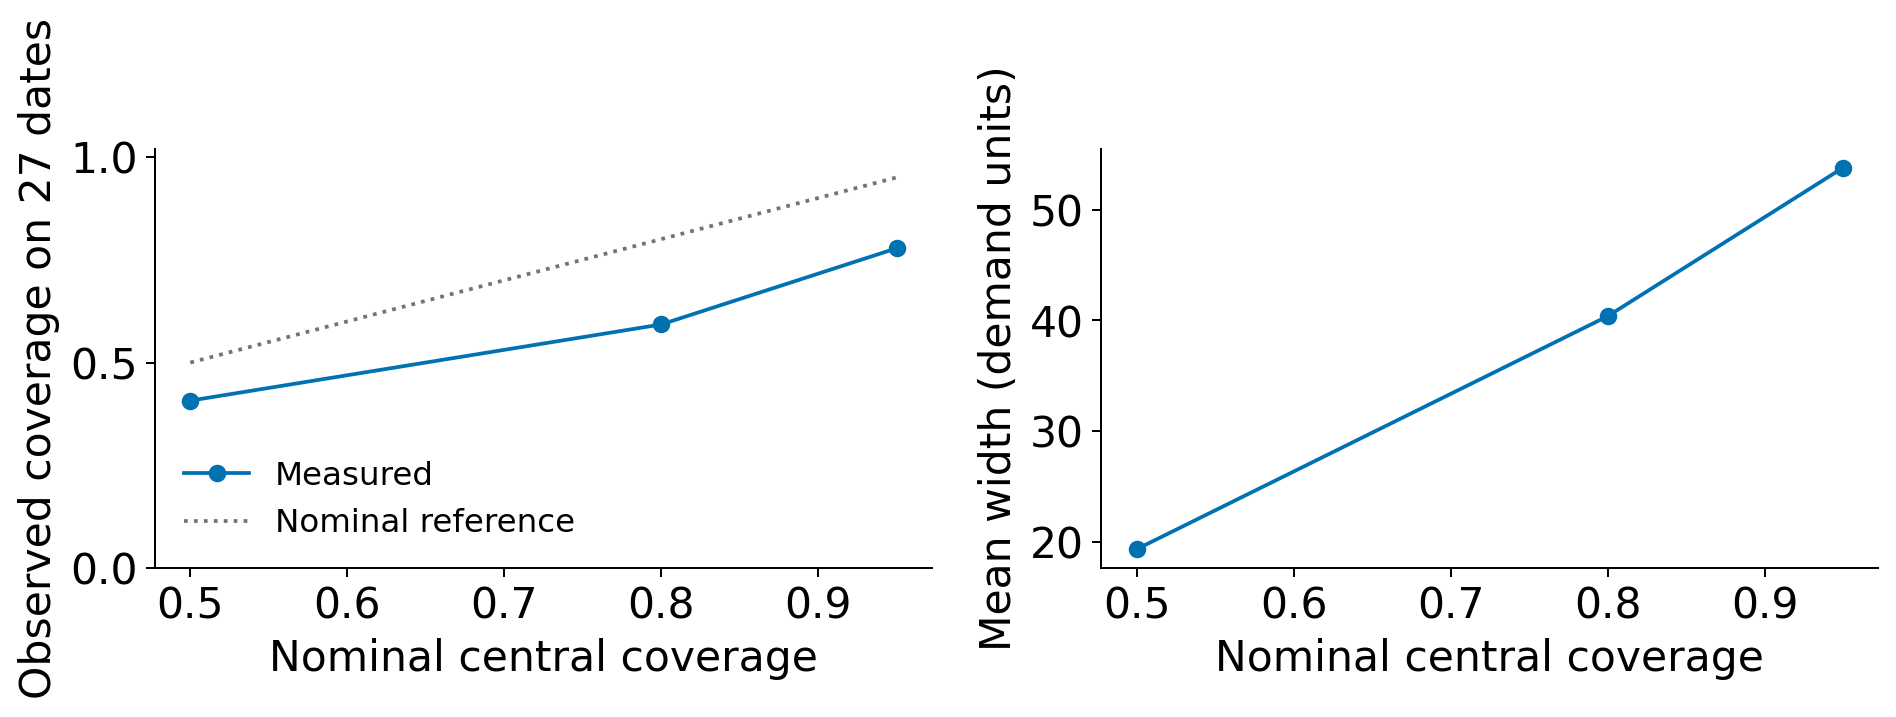

In [80]:
fig,aa=newfig(2);aa[0].plot(interval_table.nominal,interval_table.coverage,'o-',color=BLUE,label='Measured');aa[0].plot([.5,.95],[.5,.95],ls=':',color=GRAY,label='Nominal reference');aa[0].set(xlabel='Nominal central coverage',ylabel='Observed coverage on 27 dates',ylim=(0,1.02));aa[0].legend(fontsize=13)
aa[1].plot(interval_table.nominal,interval_table.mean_width,'o-',color=BLUE);aa[1].set(xlabel='Nominal central coverage',ylabel='Mean width (demand units)');finish(fig,17,'Coverage and width answer different questions')
results['5.17']={'interval_scores':interval_rows}

**Interpretation and limits.** Report width in demand units beside measured coverage. Do not tune these procedures on this already inspected assessment block.

**Separate homework reference:** HW5.17; complete its marked code blanks in the separate homework notebook.

<a id="example-5-18"></a>
## 5.18 — Make state-dependent width an explicit method

**Meaning.** A state is a condition observed at the forecast origin. State-dependent uncertainty allows forecast-error spread to depend on that condition. To vary width, estimate or model different error distributions; a constant-width band does not do this automatically. Pooled offsets use errors from both states together. Standard deviation measures spread in the same units as the error.

**Worked sequence.**
1. In a separate simulation, label each date calm or stressed before its outcome.
2. Generate zero-centered errors with standard deviations 2 and 8; these are constructed assumptions, not market estimates.
3. Estimate .10/.90 offsets from 120 calibration errors in each state.
4. Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

### 5.18.1 — Read before running

Initialize a separate seed and known calibration-state labels. Calm and stressed are conditions specified before the corresponding simulated errors are drawn.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [81]:
rng_state=np.random.default_rng(5418)
state_cal=np.repeat([0,1],120)

### 5.18.2 — Read before running

Create 60 later state labels per state and draw calibration errors using the assumed state-dependent standard deviations 2 and 8. The normal generator produces a bell-shaped error distribution centered at zero; its scale is the standard deviation. This is a stated simulation assumption, not a fitted fact about the demand data.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [82]:
state_test=np.repeat([0,1],60)
state_cal_error=rng_state.normal(0,np.where(state_cal==0,2.,8.))

### 5.18.3 — Read before running

Draw fresh later errors under the same stated simulation, then compute pooled calibration offsets. The future errors do not enter those cutoffs.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [83]:
state_test_error=rng_state.normal(0,np.where(state_test==0,2.,8.))
pooled=np.quantile(state_cal_error,[.1,.9])

### 5.18.4 — Read before running

Prepare separate result records for every state and interval method. This keeps calm and stressed coverage visible instead of reporting only an aggregate.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [84]:
state_scores=[]
state_bounds={}

### 5.18.5 — Read before running

Estimate separate offsets from calibration errors within each known state. Apply pooled and state-specific intervals to the later errors of that state, recording both coverage and width.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [85]:
for state in [0,1]:
    q=np.quantile(state_cal_error[state_cal==state],[.1,.9]);state_bounds[state]=q
    for method,bounds in [('Pooled',pooled),('State-specific',q)]:state_scores.append({'state':'Calm' if state==0 else 'Stressed','method':method,**interval_metrics(state_test_error[state_test==state],bounds[0],bounds[1])})

### 5.18.6 — Read before running

Display the computed result without refitting or changing assumptions. Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

In [86]:
print(pd.DataFrame(state_scores))

      state          method  coverage  mean_width
0      Calm          Pooled  1.000000   11.469352
1      Calm  State-specific  0.900000    5.149925
2  Stressed          Pooled  0.416667   11.469352
3  Stressed  State-specific  0.766667   19.045843


### 5.18.7 — Read before running

Draw the computed comparison: make state-dependent width an explicit method. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

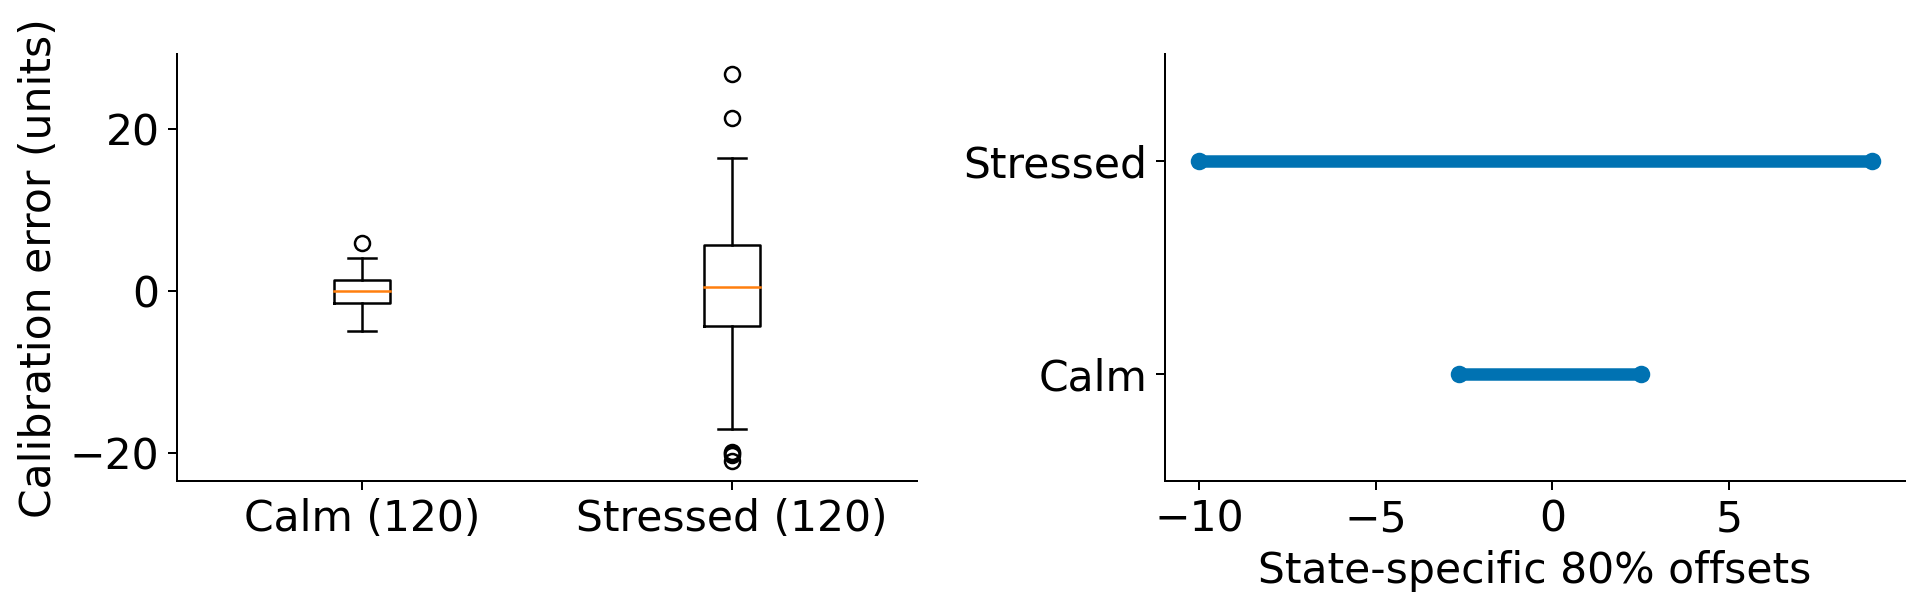

In [87]:
fig,aa=newfig(2);aa[0].boxplot([state_cal_error[state_cal==0],state_cal_error[state_cal==1]],labels=['Calm (120)','Stressed (120)']);aa[0].set(ylabel='Calibration error (units)')
for i,state in enumerate([0,1]):aa[1].plot(state_bounds[state],[i,i],color=BLUE,lw=5);aa[1].scatter(state_bounds[state],[i,i],color=BLUE)
aa[1].set(yticks=[0,1],yticklabels=['Calm','Stressed'],xlabel='State-specific 80% offsets',ylim=(-.5,1.5));finish(fig,18,'A known state can change the calibrated error spread')
results['5.18']={'state_scores':state_scores,'offsets':{str(k):v.tolist() for k,v in state_bounds.items()}}

**Interpretation and limits.** Apply pooled and state-specific offsets to 60 fresh simulated assessment errors per state, then compare coverage and width within states.

**Separate homework reference:** HW5.18; complete its marked code blanks in the separate homework notebook.

<a id="example-5-19"></a>
## 5.19 — Separate scenarios from assigned probabilities

**Meaning.** A scenario specifies a possible future input path and asks what a stated rule implies if those inputs occur. It is conditional analysis. A list of low, middle and high paths does not assign probabilities or create a prediction interval.

**Worked sequence.**
1. State a constructed demand rule: baseline 80 plus twice known traffic plus 10 when promotion is active.
2. Specify three future traffic paths for five days; keep promotion off.
3. Pass each path through the same rule.
4. Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

### 5.19.1 — Read before running

Specify the five future days and three assumed traffic paths. These arrays are scenario inputs; the code has not assigned them probabilities.

**Interpretation check:** Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

In [88]:
horizon=np.arange(1,6)
scenario_traffic={'Lower traffic':np.array([10,9,8,7,6]),'Middle traffic':np.array([10,10,10,10,10]),'Higher traffic':np.array([10,12,14,16,18])}

### 5.19.2 — Read before running

Apply the same stated baseline-plus-traffic rule to every assumed path. The outputs are conditional demand paths under those assumptions.

**Interpretation check:** Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

In [89]:
scenario_demand={name:80+2*path for name,path in scenario_traffic.items()}

### 5.19.3 — Read before running

Display the computed result without refitting or changing assumptions. Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

**Interpretation check:** Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

In [90]:
print(pd.DataFrame(scenario_demand,index=horizon))

   Lower traffic  Middle traffic  Higher traffic
1            100             100             100
2             98             100             104
3             96             100             108
4             94             100             112
5             92             100             116


### 5.19.4 — Read before running

Draw the computed comparison: separate scenarios from assigned probabilities. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

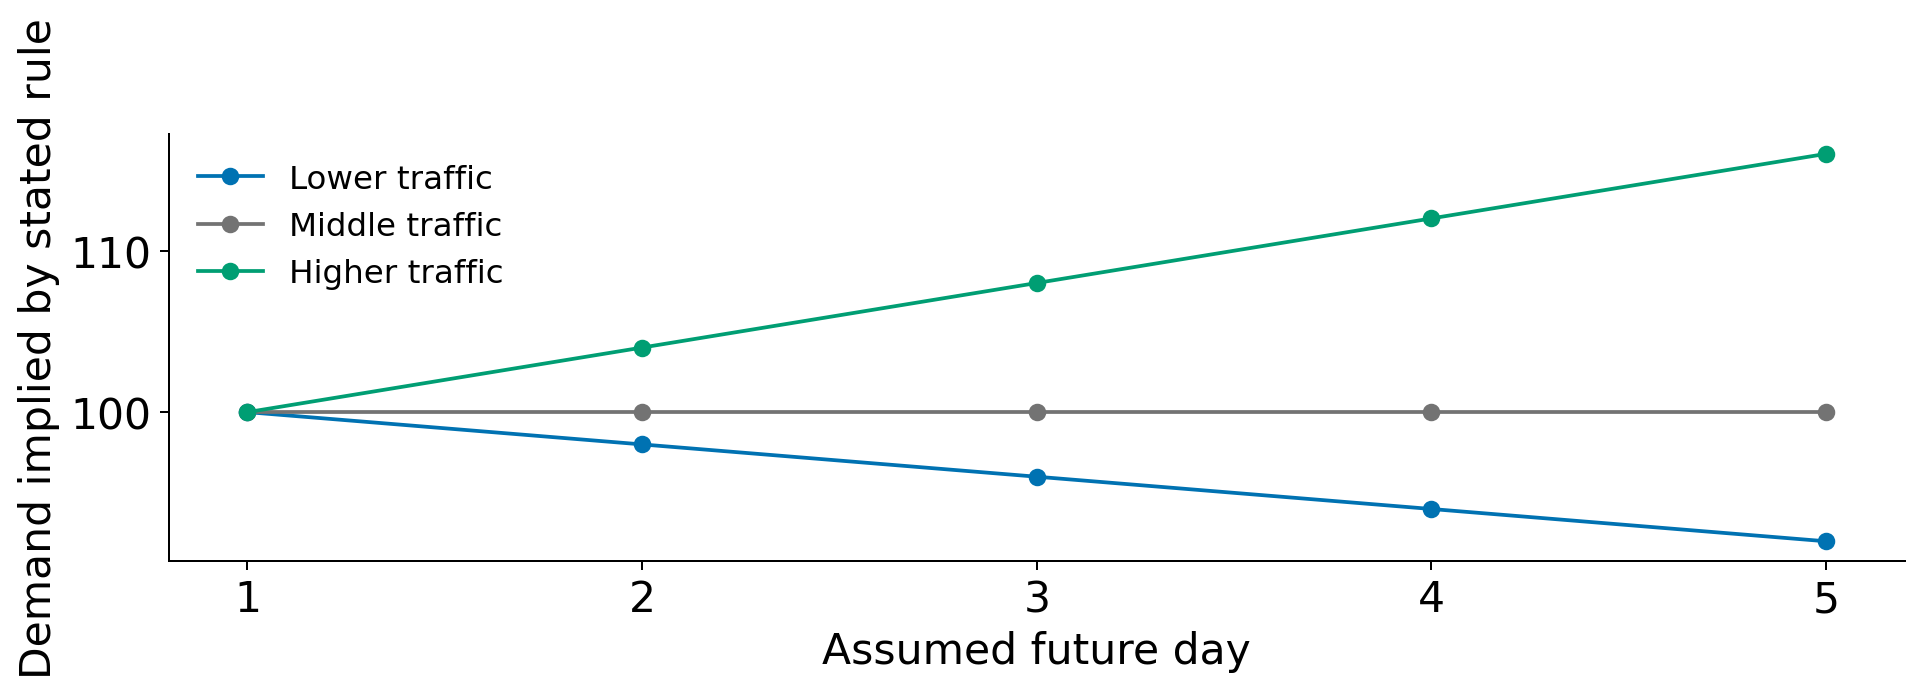

In [91]:
fig,aa=newfig();ax=aa[0]
for (name,values),color in zip(scenario_demand.items(),[BLUE,GRAY,GREEN]):ax.plot(horizon,values,'o-',label=name,color=color)
ax.set(xticks=horizon,xlabel='Assumed future day',ylabel='Demand implied by stated rule');ax.legend(fontsize=13);finish(fig,19,'Three conditional paths do not state probabilities')
results['5.19']={'scenario_paths':{k:v.tolist() for k,v in scenario_demand.items()},'probabilities_assigned':False}

**Interpretation and limits.** Label the resulting paths as assumed scenarios, not 80% or 95% bounds. Forecasting future inputs is a separate task.

**Separate homework reference:** HW5.19; complete its marked code blanks in the separate homework notebook.

<a id="example-5-20"></a>
## 5.20 — Do not add daily interval endpoints into a weekly interval

**Meaning.** A joint distribution describes outcomes together, including their dependence. A distribution of weekly total demand requires joint daily paths. Separate daily quantiles alone do not specify that distribution. Dependence means that knowing one outcome can change the probability distribution of another.

**Worked sequence.**
1. Construct 5000 seven-day paths with daily mean demand 100 and error standard deviation 5.
2. In one environment daily errors are independent; in another all seven share the same error.
3. Sum demand within each path and then take the .10/.90 quantiles of totals.
4. The common-error weekly interval is much wider even though every day has the same marginal error distribution.

### 5.20.1 — Read before running

Draw 5000 independent-error seven-day paths under the stated seed and daily mean/spread. Each row is one possible complete week.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

In [92]:
rng_paths=np.random.default_rng(5420)
independent_paths=100+rng_paths.normal(0,5,(5000,7))

### 5.20.2 — Read before running

Draw one error per simulated week and repeat it across all seven days. This changes the dependence while retaining each day's marginal error spread.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

In [93]:
common_draw=rng_paths.normal(0,5,(5000,1))
common_paths=100+np.repeat(common_draw,7,axis=1)

### 5.20.3 — Read before running

Sum demand across the seven columns within each path. Repeat the same within-path operation for the shared-error environment.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

In [94]:
independent_totals=independent_paths.sum(axis=1)
common_totals=common_paths.sum(axis=1)

### 5.20.4 — Read before running

Take .10/.90 quantiles of the total-demand arrays after summing. The two intervals answer questions about weekly totals, not isolated daily outcomes.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

In [95]:
weekly_intervals={'Independent':np.quantile(independent_totals,[.1,.9]),'Common error':np.quantile(common_totals,[.1,.9])}

### 5.20.5 — Read before running

Display the computed result without refitting or changing assumptions. The common-error weekly interval is much wider even though every day has the same marginal error distribution.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

In [96]:
print(weekly_intervals)

{'Independent': array([683.34439081, 717.83486648]), 'Common error': array([654.1355349 , 745.10869212])}


### 5.20.6 — Read before running

Draw the computed comparison: do not add daily interval endpoints into a weekly interval. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

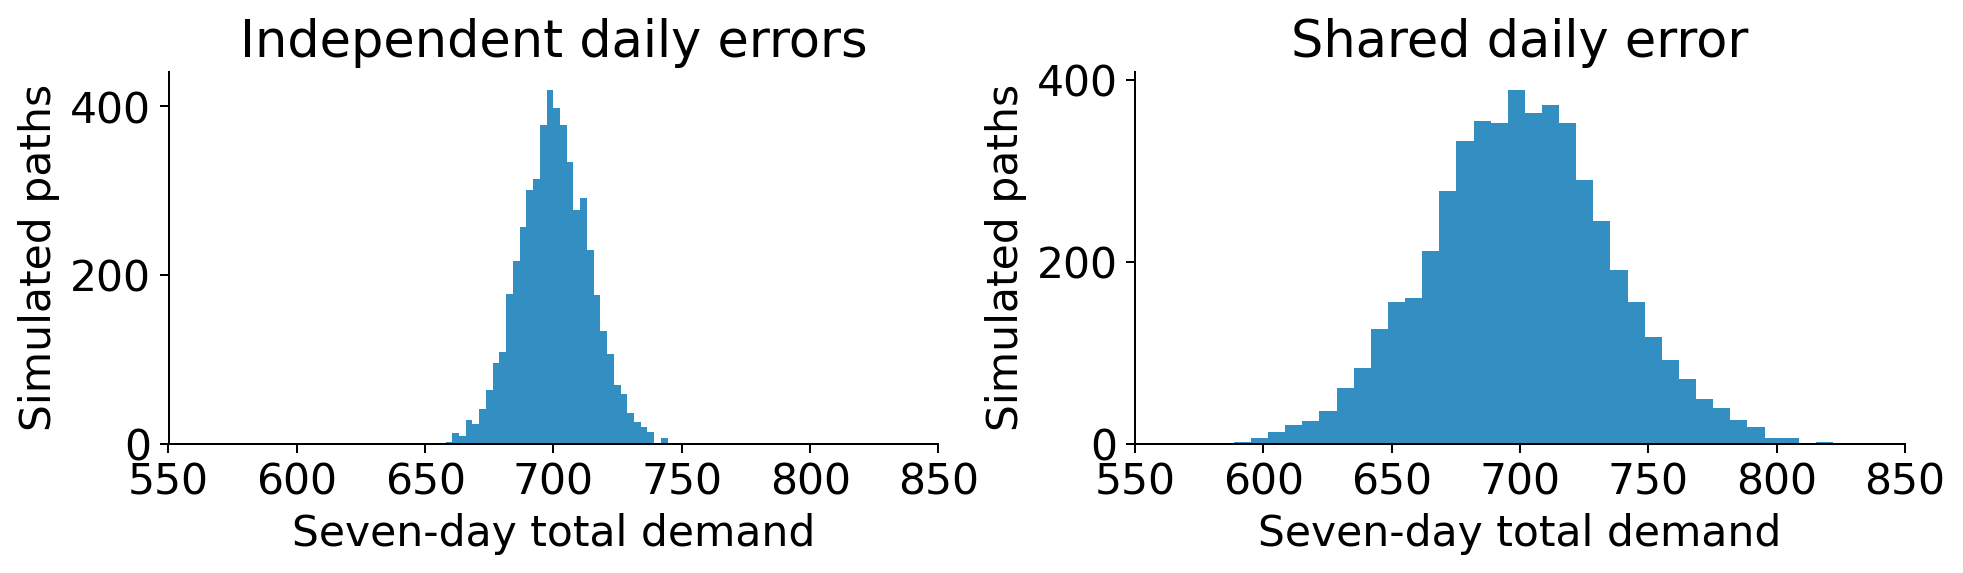

In [97]:
fig,aa=newfig(2)
for ax,values,label in zip(aa,[independent_totals,common_totals],['Independent daily errors','Shared daily error']):ax.hist(values,bins=35,color=BLUE,alpha=.8);ax.set(title=label,xlabel='Seven-day total demand',ylabel='Simulated paths');ax.set_xlim(550,850)
finish(fig,20,'Dependence changes uncertainty about a sum')
results['5.20']={'weekly_intervals':{k:v.tolist() for k,v in weekly_intervals.items()},'paths_per_environment':5000}

**Interpretation and limits.** The common-error weekly interval is much wider even though every day has the same marginal error distribution.

**Separate homework reference:** HW5.20; complete its marked code blanks in the separate homework notebook.

<a id="example-5-21"></a>
## 5.21 — State a threshold rule without inventing an action size

**Meaning.** A threshold rule maps a forecast feature to a specified response. A prediction interval can trigger review under such a rule, but it does not by itself determine the economically optimal quantity or the size of a financial position.

**Worked sequence.**
1. Keep the same point forecast, 100, in two constructed cases.
2. Give the cases lower interval bounds 90 and 60.
3. Specify in advance that a lower bound below 80 triggers a capacity-plan review.
4. Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

### 5.21.1 — Read before running

Hold the central forecast at 100 in two cases and specify their lower interval endpoints separately.

**Interpretation check:** Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

In [98]:
decision_points=np.array([100,100])
decision_lower=np.array([90,60])

### 5.21.2 — Read before running

Complete the interval endpoints and apply the prespecified strict lower-bound-below-80 rule. The result is a review signal rather than a derived action quantity.

**Interpretation check:** Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

In [99]:
decision_upper=np.array([110,140])
review_trigger=decision_lower<80

### 5.21.3 — Read before running

Display the computed result without refitting or changing assumptions. Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

**Interpretation check:** Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

In [100]:
print(pd.DataFrame({'point':decision_points,'lower':decision_lower,'upper':decision_upper,'review':review_trigger}))

   point  lower  upper  review
0    100     90    110   False
1    100     60    140    True


### 5.21.4 — Read before running

Draw the computed comparison: state a threshold rule without inventing an action size. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

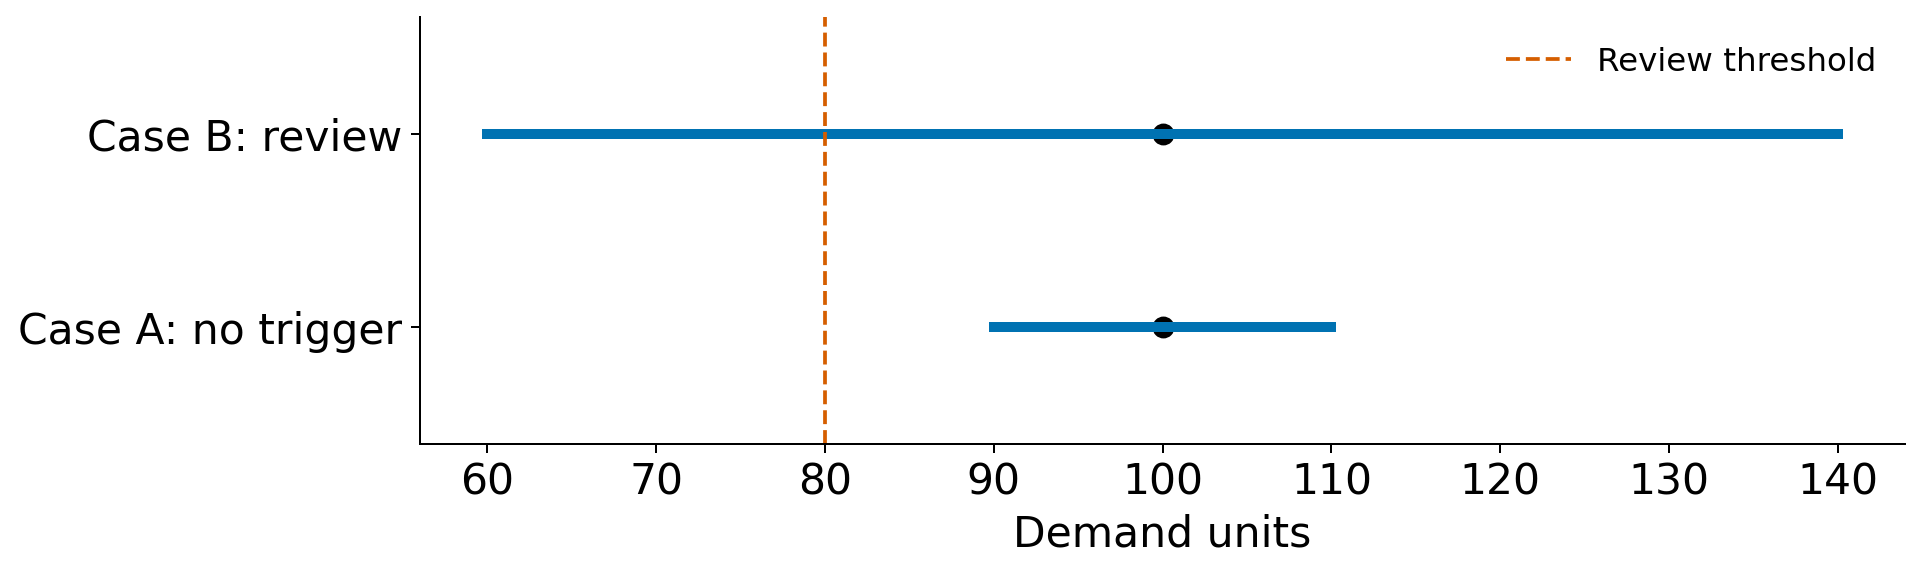

In [101]:
fig,aa=newfig();ax=aa[0]
for i,(lo,hi) in enumerate(zip(decision_lower,decision_upper)):ax.plot([lo,hi],[i,i],color=BLUE,lw=4);ax.scatter([100],[i],color='black',s=60)
ax.axvline(80,color=ORANGE,ls='--',label='Review threshold');ax.set(yticks=[0,1],yticklabels=['Case A: no trigger','Case B: review'],xlabel='Demand units',ylim=(-.6,1.6));ax.legend(fontsize=13);finish(fig,21,'The same center can produce a different review signal')
results['5.21']={'review_trigger':review_trigger.tolist(),'threshold':80}

**Interpretation and limits.** Only the second case triggers. The rule says review, not an unexplained 20% reduction or a guaranteed loss limit.

**Separate homework reference:** HW5.21; complete its marked code blanks in the separate homework notebook.

<a id="example-5-22"></a>
## 5.22 — Stress the cost assumptions before recommending

**Meaning.** Sensitivity analysis repeats a calculation under explicitly changed assumptions. Robustness means checking how much the conclusion depends on those assumptions; it does not mean a guarantee against every future change.

**Worked sequence.**
1. Keep the same three outcomes and their stated probabilities.
2. Compare shortage/excess cost ratios 1:1,3:1,1:3.
3. Recalculate expected cost over a common action grid for each ratio.
4. Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

### 5.22.1 — Read before running

Set a common candidate-stock grid and a result container for every cost assumption. Comparable actions and outcome probabilities remain fixed.

**Interpretation check:** Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

In [102]:
sensitivity_grid=np.arange(60,151)
sensitivity=[]

### 5.22.2 — Read before running

For each stated cost pair, recalculate expected loss and locate its minimum on the same grid. Store both the selected quantity and the implied expected cost.

**Interpretation check:** Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

In [103]:
sensitivity_curves={}
for cu,co in cost_pairs:
    curve=loss(demand_cases[None,:],sensitivity_grid[:,None],cu,co)@probabilities;sensitivity_curves[f'{cu}:{co}']=curve
    sensitivity.append({'shortage':cu,'excess':co,'chosen_stock':int(sensitivity_grid[np.argmin(curve)]),'expected_cost':float(curve.min())})

### 5.22.3 — Read before running

Display the computed result without refitting or changing assumptions. Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

**Interpretation check:** Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

In [104]:
print(pd.DataFrame(sensitivity))

   shortage  excess  chosen_stock  expected_cost
0         1       1           100           16.0
1         3       1           140           32.0
2         1       3           100           24.0


### 5.22.4 — Read before running

Draw the computed comparison: stress the cost assumptions before recommending. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

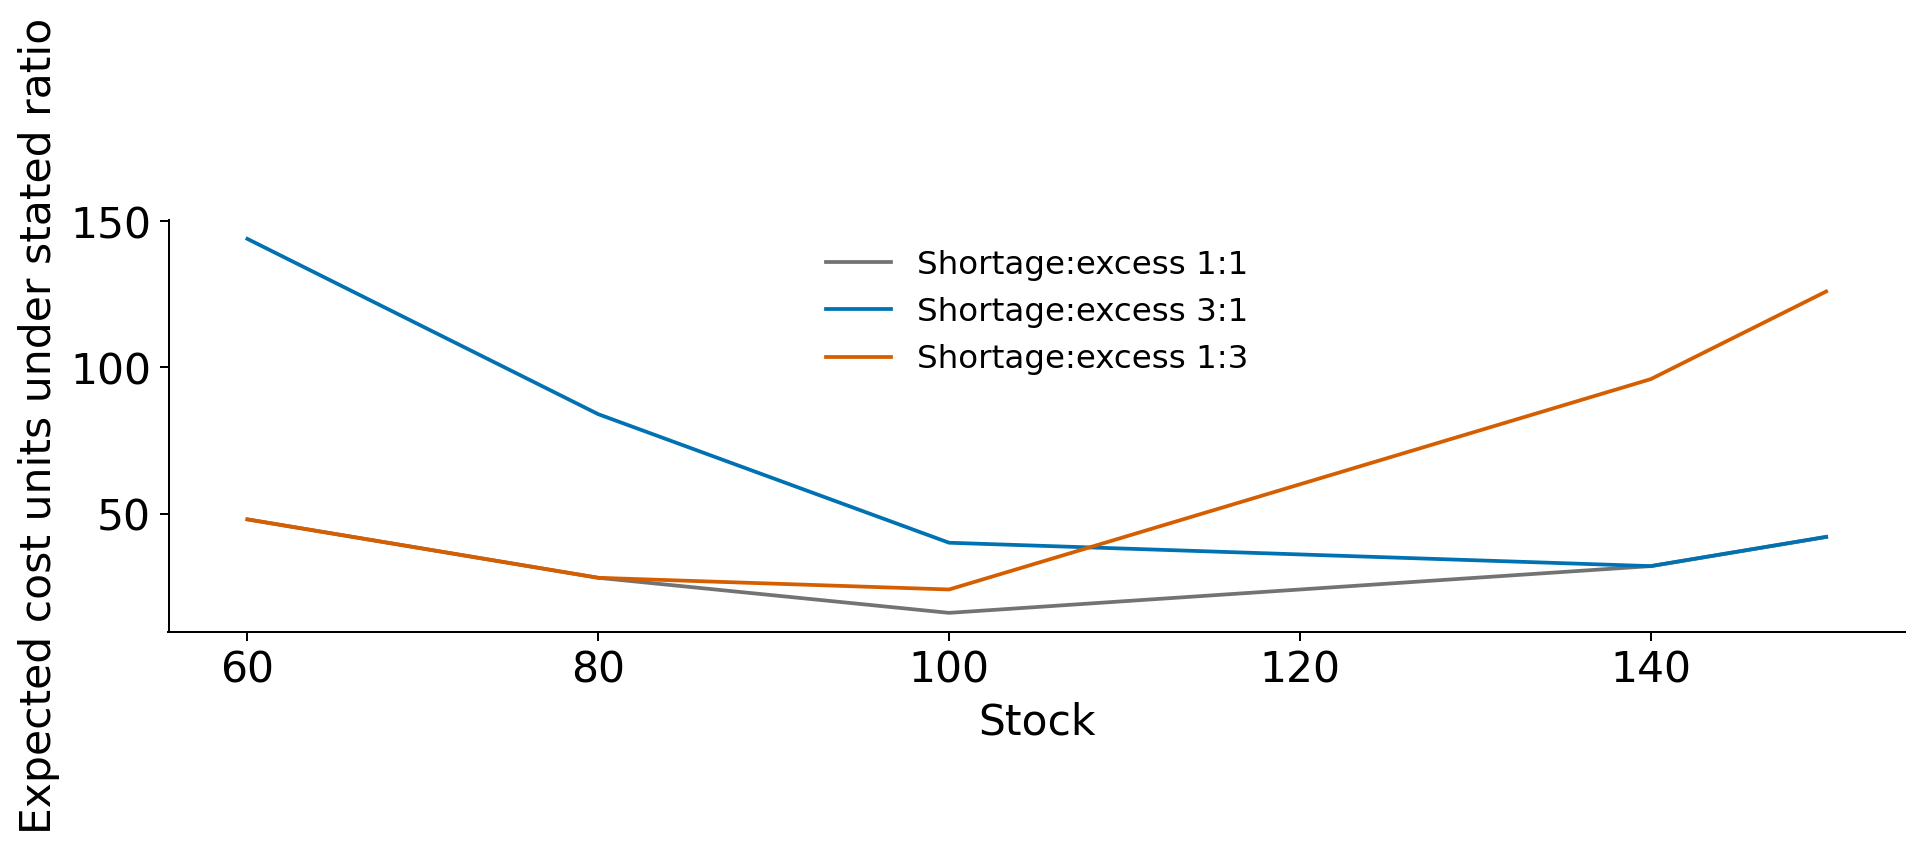

In [105]:
fig,aa=newfig();ax=aa[0]
for (label,curve),color in zip(sensitivity_curves.items(),[GRAY,BLUE,ORANGE]):ax.plot(sensitivity_grid,curve,color=color,label='Shortage:excess '+label)
ax.set(xlabel='Stock',ylabel='Expected cost units under stated ratio');ax.legend(fontsize=13);finish(fig,22,'Recommendations can depend on the cost ratio')
results['5.22']={'cost_sensitivity':sensitivity}

**Interpretation and limits.** Report the chosen actions and what changed. These cost scenarios are assumptions, not facts learned from the demand file.

**Separate homework reference:** HW5.22; complete its marked code blanks in the separate homework notebook.

<a id="example-5-23"></a>
## 5.23 — Evaluate a residual-quantile action adjustment honestly

**Meaning.** A conditional quantile is an outcome cutoff given the inputs known at the forecast origin. Adding a calibration-error quantile to a point forecast estimates a cost-sensitive action by assuming that earlier errors remain relevant across future input conditions. It is not automatically the true conditional quantile for every case.

**Worked sequence.**
1. Prespecify linear, selected-tree and forest fitting settings from Lecture 4.
2. Fit each model on training only and estimate its .75 error offset from calibration only.
3. Compare unadjusted and adjusted actions on the same 27 later assessment dates.
4. Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

**Selection history:** Lecture 4 chose the tree setting using the same 27-date block now reused for calibration. These results demonstrate a procedure on previously inspected teaching data; they do not claim independent post-selection calibration. A new study should separate tuning, calibration and later assessment, or evaluate its reuse explicitly.

### 5.23.1 — Read before running

Specify the linear, selected-tree and forest procedures before the assessment calculation. Their training settings are carried forward from Lecture 4, not chosen by the assessment outcome.

**Interpretation check:** Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

In [106]:
fixed_models={'Linear':make_pipeline(StandardScaler(),LinearRegression()),'Tree':DecisionTreeRegressor(max_depth=5,min_samples_leaf=4,random_state=417),'Forest':RandomForestRegressor(n_estimators=100,max_depth=5,min_samples_leaf=8,max_features=1,random_state=417,n_jobs=1)}
policy_rows=[]

### 5.23.2 — Read before running

Fit each procedure on training, estimate its error-quantile adjustment on calibration and save later center/adjusted actions. Score both actions on the same assessment cases.

**Interpretation check:** Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

In [107]:
policy_predictions={}
for name,m in fixed_models.items():
    m.fit(train[features],train.demand);ce=cal.demand.to_numpy()-m.predict(cal[features]);offset=float(np.quantile(ce,.75));center=m.predict(assessment[features]);adjusted=center+offset
    policy_predictions[name]={'point':center,'adjusted':adjusted,'offset':offset}
    policy_rows.append({'model':name,'calibration_offset':offset,'point_cost':float(loss(assessment.demand,center).mean()),'adjusted_cost':float(loss(assessment.demand,adjusted).mean())})

### 5.23.3 — Read before running

Display the computed result without refitting or changing assumptions. Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

**Interpretation check:** Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

In [108]:
print(pd.DataFrame(policy_rows))

    model  calibration_offset  point_cost  adjusted_cost
0  Linear           25.624900   75.002302      32.578209
1    Tree           20.931714   80.577290      43.315965
2  Forest           32.164220   90.656508      34.137260


### 5.23.4 — Read before running

Draw the computed comparison: evaluate a residual-quantile action adjustment honestly. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

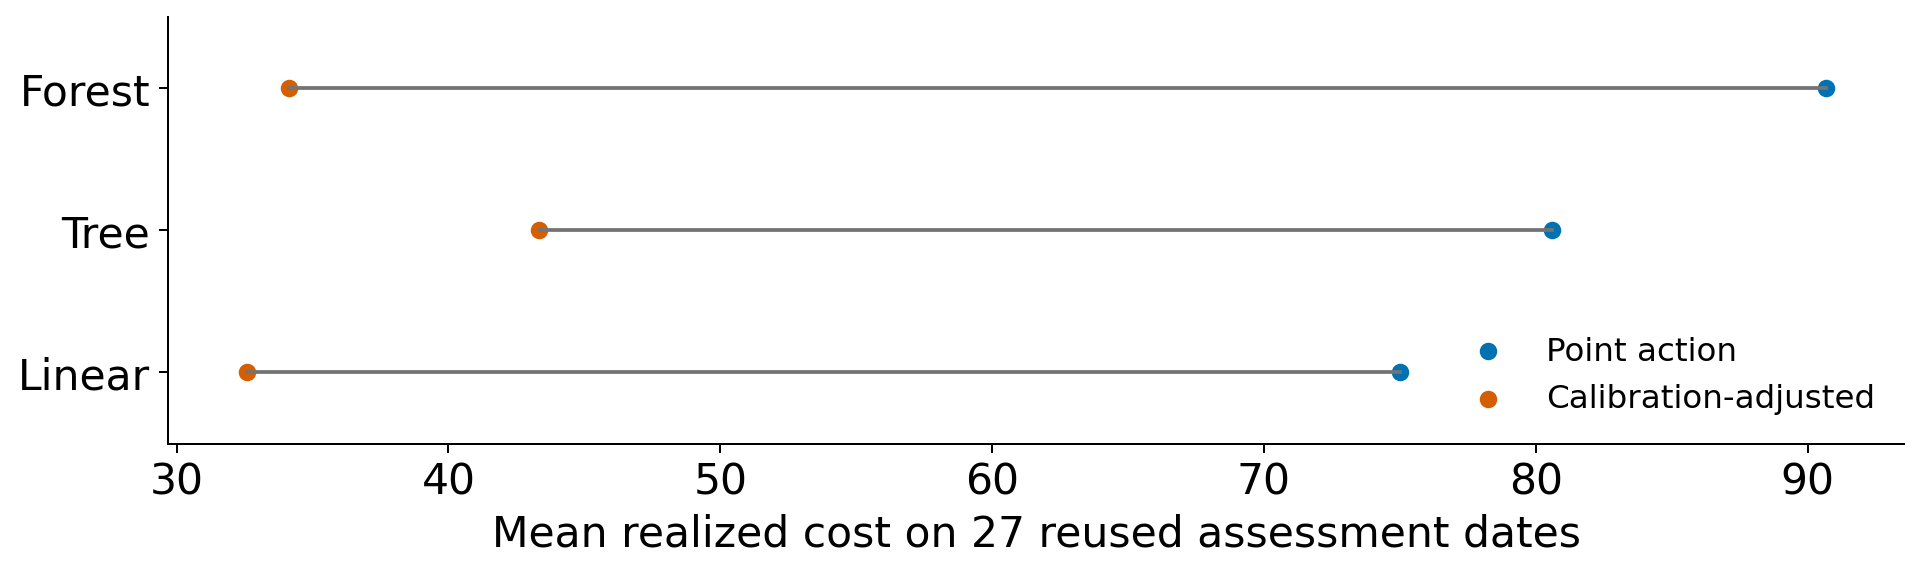

In [109]:
fig,aa=newfig();ax=aa[0]
for i,r in enumerate(policy_rows):ax.plot([r['point_cost'],r['adjusted_cost']],[i,i],color=GRAY);ax.scatter([r['point_cost']],[i],color=BLUE,label='Point action' if i==0 else None);ax.scatter([r['adjusted_cost']],[i],color=ORANGE,label='Calibration-adjusted' if i==0 else None)
ax.set(yticks=range(3),yticklabels=list(fixed_models),xlabel='Mean realized cost on 27 reused assessment dates',ylim=(-.5,2.5));ax.legend(fontsize=13);finish(fig,23,'Measure policy loss rather than promising improvement')
results['5.23']={'policy_scores':policy_rows}

**Interpretation and limits.** Report measured business loss without choosing a winning policy from this previously inspected block. Do not assume the adjustment must improve realized cost.

**Separate homework reference:** HW5.23; complete its marked code blanks in the separate homework notebook.

<a id="example-5-24"></a>
## 5.24 — Write a recommendation that can be audited

**Meaning.** An auditable recommendation records the information set, forecasting assumptions, available actions, cost rule, uncertainty, chosen action and the condition for review. It separates an assumption from a measured result.

**Worked sequence.**
1. Reuse the three-outcome decision example; expected demand is 108 and median demand is 100.
2. State costs 3 and 1 and capacity 120.
3. Recommend feasible stock 120 with expected cost 36 under the stated probabilities.
4. Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

### 5.24.1 — Read before running

Assemble the mean, median, explicit costs, capacity, feasible action and conditional expected cost from the already computed worked example. Keep assumed information and measured arithmetic distinguishable.

**Interpretation check:** Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

In [110]:
memo={'information':'Three assumed demand cases, before demand is observed','mean_demand':float(demand_cases@probabilities),'median_demand':demand_quantile(.5),'shortage_cost':3,'excess_cost':1,'capacity':120,'recommended_stock':best_feasible,'expected_cost':float(feasible_expected.min()),'review_condition':'Changed demand support, changed costs or unavailable capacity'}

### 5.24.2 — Read before running

Display the computed result without refitting or changing assumptions. Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

**Interpretation check:** Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

In [111]:
print(json.dumps(memo,indent=2))

{
  "information": "Three assumed demand cases, before demand is observed",
  "mean_demand": 108.0,
  "median_demand": 100.0,
  "shortage_cost": 3,
  "excess_cost": 1,
  "capacity": 120,
  "recommended_stock": 120,
  "expected_cost": 36.0,
  "review_condition": "Changed demand support, changed costs or unavailable capacity"
}


### 5.24.3 — Read before running

Draw the computed comparison: write a recommendation that can be audited. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

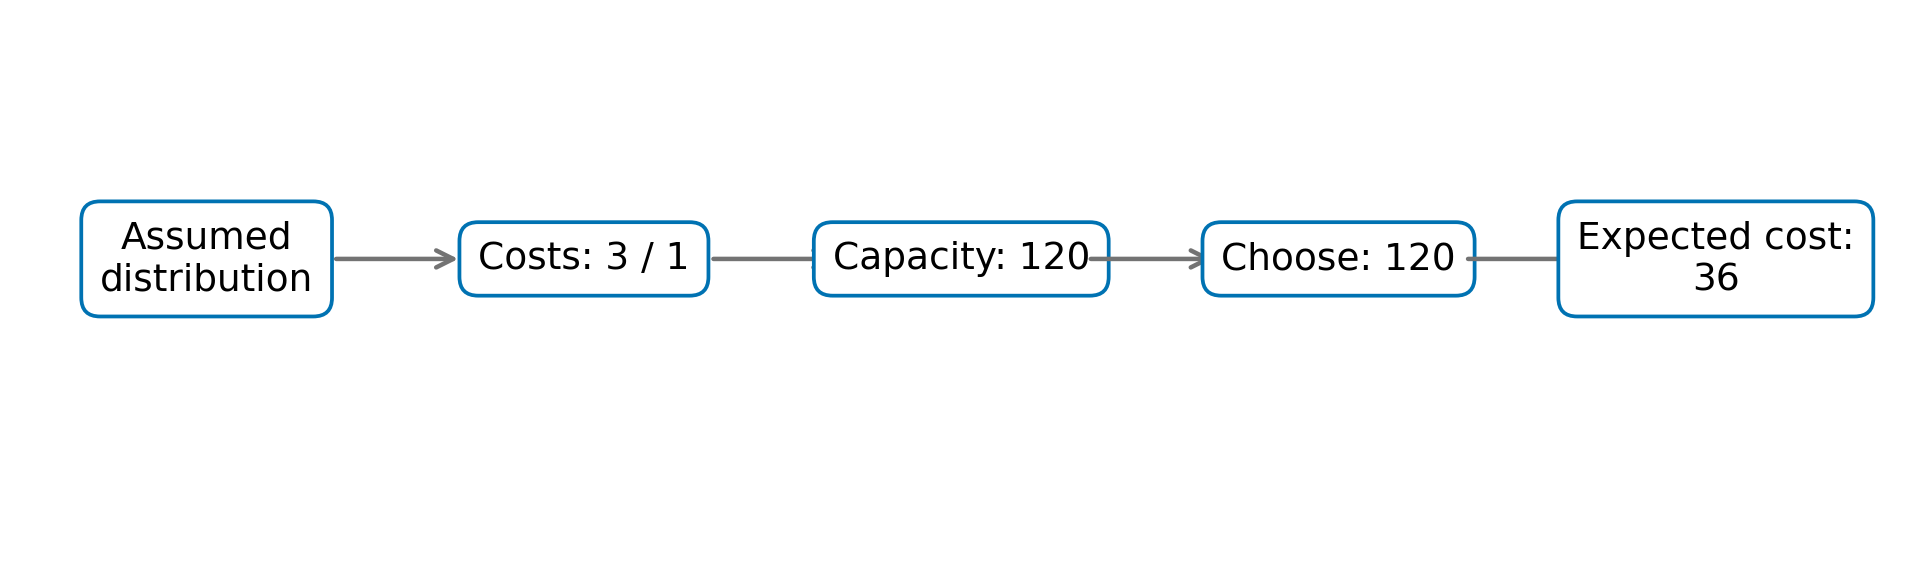

In [112]:
fig,aa=newfig();schema(aa[0],['Assumed distribution','Costs: 3 / 1','Capacity: 120','Choose: 120','Expected cost: 36'])
finish(fig,24,'Make every part of a recommendation traceable')
results['5.24']=memo

**Interpretation and limits.** Record the limitations: probabilities are assumed, capacity binds, and the realized outcome can differ from the mean.

**Separate homework reference:** HW5.24; complete its marked code blanks in the separate homework notebook.

<a id="example-5-25"></a>
## 5.25 — Replay decisions before attaching later outcomes

**Meaning.** A decision record stores what was known and chosen at the forecast origin. A later evaluation attaches the outcome only after the decision has been saved. This ordering prevents hindsight from silently changing the earlier recommendation.

**Worked sequence.**
1. Use the fixed linear model and its calibration offset from 5.23.
2. Save target date, prior-day forecast origin, point forecast, interval and planned stock before joining outcomes.
3. Apply a stated capacity of 400 units and nonnegative stock; these are illustrative operational limits.
4. Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

### 5.25.1 — Read before running

Retrieve the stored linear policy and create the decision record with earlier origins, later targets, saved forecast bounds and capacity-limited stock.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [113]:
linear_policy=policy_predictions['Linear']
record=pd.DataFrame({'target_date':assessment.index,'forecast_origin':assessment.index-pd.Timedelta(days=1),'point':linear_policy['point'],'lower80':lo80,'upper80':hi80,'stock':np.clip(linear_policy['adjusted'],0,400)})

### 5.25.2 — Read before running

Verify the recorded information order, then save the decision table before outcomes are attached. The exported file contains the action as originally made.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [114]:
assert (record.forecast_origin<record.target_date).all()
record.to_csv(OUT/'decisions_before_outcomes.csv',index=False)

### 5.25.3 — Read before running

Only after saving the decisions, attach observed demand and calculate realized cost. This ordering prevents the outcome from silently changing the earlier action.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [115]:
record['observed_demand']=assessment.demand.to_numpy()
record['realized_cost']=loss(record.observed_demand,record.stock)

### 5.25.4 — Read before running

Export the later evaluation audit with both the original decision and its observed consequence. Keep it separate from the decision-before-outcome file.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [116]:
record.to_csv(OUT/'decision_audit.csv',index=False)

### 5.25.5 — Read before running

Display the computed result without refitting or changing assumptions. Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [117]:
print(record.head().to_string(index=False))

target_date forecast_origin      point    lower80    upper80      stock  observed_demand  realized_cost
 2024-06-02      2024-06-01 312.199703 305.021396 345.406807 337.824603           350.40      37.726191
 2024-06-03      2024-06-02 350.717849 343.539542 383.924952 376.342749           350.78      25.562749
 2024-06-04      2024-06-03 333.151731 325.973424 366.358834 358.776631           367.69      26.740107
 2024-06-05      2024-06-04 347.940442 340.762136 381.147546 373.565342           398.93      76.093973
 2024-06-06      2024-06-05 366.838596 359.660289 400.045699 392.463496           376.72      15.743496


### 5.25.6 — Read before running

Display the computed result without refitting or changing assumptions. Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [118]:
print('Mean realized cost:',record.realized_cost.mean())

Mean realized cost: 32.11273649112768


### 5.25.7 — Read before running

Draw the computed comparison: replay decisions before attaching later outcomes. Read the labeled axes or process stages, save the exact figure reused by the notes and slides, and retain the worked numeric result.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

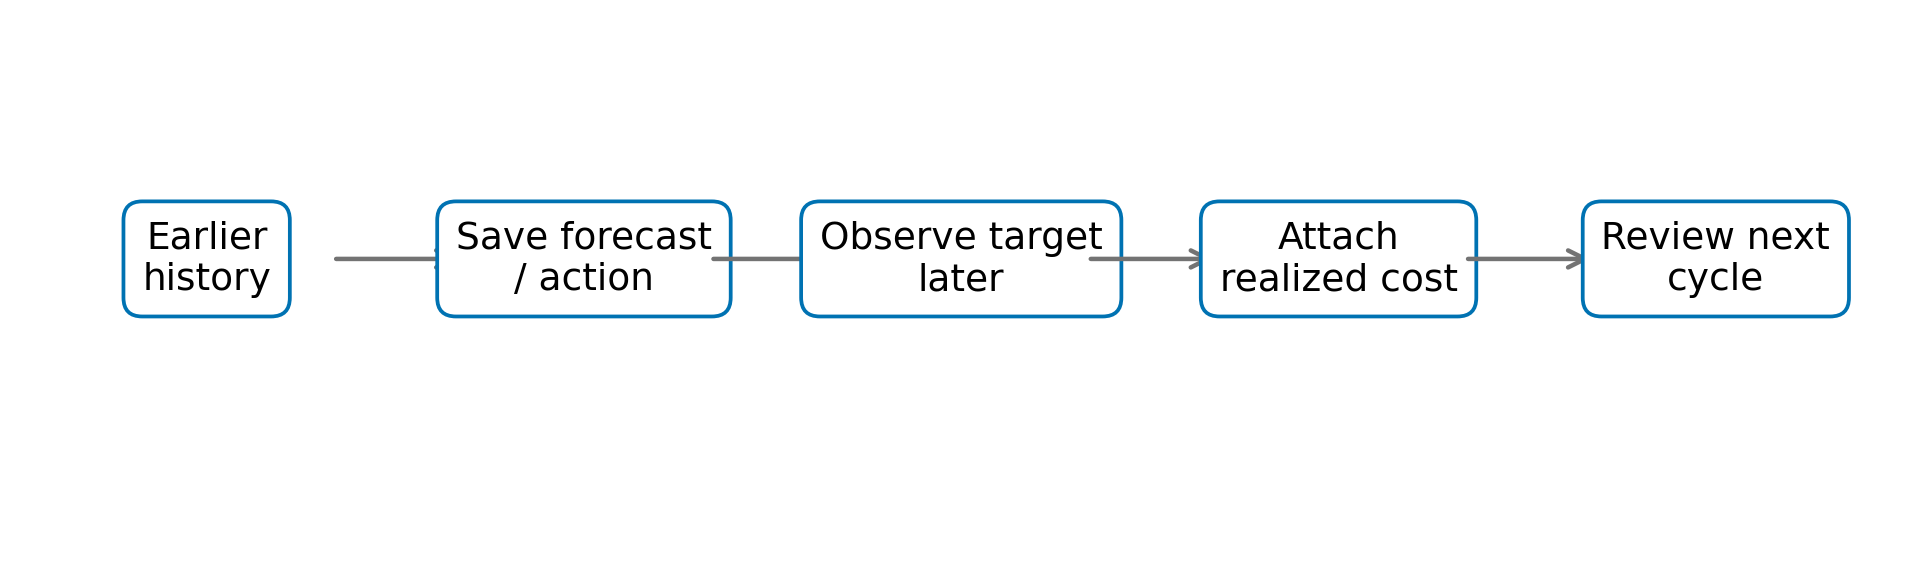

In [119]:
fig,aa=newfig();schema(aa[0],['Earlier history','Save forecast / action','Observe target later','Attach realized cost','Review next cycle'])
finish(fig,25,'Preserve the order of information, action and evaluation')
results['5.25']={'decision_rows':len(record),'mean_cost':float(record.realized_cost.mean()),'capacity':400,'all_origins_before_targets':bool((record.forecast_origin<record.target_date).all())}

**Interpretation and limits.** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

**Separate homework reference:** HW5.25; complete its marked code blanks in the separate homework notebook.

### 5.25.8 — Read before running

Export the computed numerical examples and the matching figure inventory for the notes/slides consistency check.

**Interpretation check:** Then attach realized demand and compute cost. Export the record for the integrated rolling evaluation in Lecture 6; do not refit using this assessment outcome.

In [120]:
(OUT/'worked_values.json').write_text(json.dumps(results,indent=2))
(GRAPH/'figure_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved',len(results),'worked examples and',len(manifest),'matching figures.')
np.savez_compressed(OUT/'illustration_arrays.npz',traffic=traffic,sales=sales,query_grid=grid,tree_grid=stump.predict(grid[:,None]),linear_grid=trend.predict(grid[:,None]),monitor_actual=monitor_actual,past_mae=past_mae.to_numpy(),independent_paths=independent_paths,common_paths=common_paths,cal_error=cal_error,assessment_point=assessment_point,assessment_actual=assessment.demand.to_numpy(),lo80=lo80,hi80=hi80,state_cal_error=state_cal_error,state_cal=state_cal)

Saved 25 worked examples and 25 matching figures.
